# CAES Mini-Project: Variant 1b System Design and Simulation

Compressed Air Energy Storage (CAES) stores electricity during off-peak hours by compressing ambient air into a storage reservoir. During discharge, the compressed air is extracted, heated via a combustor, and expanded through a turbine to generate electricity.

## Variant 1b Description

**Variant 1b** models a single-stage, non-adiabatic CAES plant with a constant-pressure reservoir:

* **Charge:** Ambient air is compressed in a single-stage compressor directly to the storage pressure $P_{\text{max}}$. The heat of compression is removed via a water cooler and rejected to ambient (no thermal storage), bringing the air towards ambient temperature before storage.

* **Discharge:** Air leaves the store at a constant inlet pressure of 16 bar (quasi-steady expansion). A fuel combustor heats the air from near ambient conditions up to the turbine inlet temperature ($550^\circ\text{C}$) before it expands across a single turbine stage to ambient pressure.

## System Specifications & Given Parameters

| Category | Parameter | Symbol | Value | Unit / Description |
|---|---|---|---|---|
| **Fluid Properties** | Working fluid | — | Air | Real-gas properties via CoolProp (`"Air"`) |
| **Ambient Conditions** | Ambient temperature | $T_0$ | 15 (288.15) | °C (K) |
| | Ambient pressure | $P_0$ | 1.013 | bar (compressor inlet / turbine exhaust) |
| **Storage Conditions** | Storage / max pressure | $P_{\text{max}}$ | 16 | bar (held constant during operation) |
| | Reservoir thermal state | $T_{\text{res}}$ | 15 (288.15) | °C (assumed returns and remains at $T_0$) |
| **Operating Targets** | Discharge shaft power | $P_{\text{shaft}}$ | 1 | MW |
| | Discharge duration | $\Delta t_{\text{dis}}$ | 4 | h (delivers 4 MWh per cycle) |
| | Charge duration | $\Delta t_{\text{ch}}$ | 4 | h (governs charge mass flow rate) |
| **Component Efficiencies** | Compressor isentropic efficiency | $\eta_{\text{is,c}}$ | 0.85 | Single stage |
| | Turbine isentropic efficiency | $\eta_{\text{is,t}}$ | 0.88 | Single stage |
| | Mechanical / generator efficiency | $\eta_{\text{mech}}$ | 0.98 | Shaft transmission / generator conversion |
| **Thermal Parameters** | Cooler pinch | $\Delta T_{\text{pinch}}$ | 10 | K (air cooled towards $T_0 + 10\text{ K}$) |
| | Turbine inlet temperature | TIT | 550 (823.15) | °C (K), achieved via direct heat addition |
| | Reference fuel-to-electricity efficiency | $\eta_f$ | 0.40 | Metric weighting factor for fuel input |


# 1. Environment Setup & Thermodynamic Backends


In [160]:
# --- Imports ---
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from CoolProp.CoolProp import PropsSI

import caldis
from caldis.core.system import System
from caldis.components import FluidBoundary, Compressor, SizingHX, CombustionChamber, Turbine
from caldis.components.vessels.tank import TankConstP
from caldis.fluids import CoolPropBackend
from caldis.solvers import simulate

# --- Fluid Property Backends (CoolProp) ---
be_air = CoolPropBackend("Air")
be_fuel = CoolPropBackend("Methane")
be_water = CoolPropBackend("Water")


# 2. Plant Baseline Specifications & Operating Targets
Defines ambient boundary conditions, target power output, cycle durations, and nominal component efficiencies.


In [161]:
# ==============================================================================
# Global Ambient Boundary Conditions
# ==============================================================================
# [Thermodynamic State] Ambient temperature (15 °C)
T0 = 15.0 + 273.15           # [K]
# [Thermodynamic State] Ambient pressure (1.013 bar)
P0 = 1.013e5                 # [Pa]

# ==============================================================================
# Operational Cycle Targets
# ==============================================================================
# [Energy Rate / Power] Target turbine net shaft electrical power output
W_target = 1.0e6             # [W] (1 MW target)
# [Time Duration] Target discharge cycle duration (4 hours -> 4 MWh energy delivery)
t_discharge = 4.0 * 3600.0   # [s]
# [Time Duration] Target charge cycle duration (4 hours)
t_charge = 4.0 * 3600.0      # [s]

# ==============================================================================
# Cycle Operating Limits & Component Efficiencies
# ==============================================================================
# [Pressure Parameter] Nominal storage reservoir pressure (held isobaric)
Pmax = 16.0e5                # [Pa] 
# [Temperature Parameter] Turbine Inlet Temperature (TIT)
Ttit = 550.0 + 273.15        # [K] 
# [Temperature Parameter] Cooler approach pinch temperature difference
delta_T_pinch = 10.0         # [K] 

# [Efficiency Parameter] Single-stage compressor isentropic efficiency
Eta_ISC = 0.85               
# [Efficiency Parameter] Single-stage turbine isentropic efficiency
Eta_IST = 0.88               
# [Efficiency Parameter] Mechanical shaft / generator electrical efficiency
Eta_Mech = 0.98              
# [Efficiency Parameter] Reference fuel-to-electricity conversion efficiency
Eta_Fuel = 0.40               


# 3. Discharge Subsystem: Design, Sizing & Dynamic Simulation
The discharge cycle extracts compressed air from the isobaric reservoir, combusts methane fuel to reach $550^\circ\text{C}$ TIT, and expands the flue gas through the turbine down to ambient backpressure ($P_0$) to deliver 1 MW of electricity.


In [162]:
# ==============================================================================
# Discharge Thermodynamic States & Expansion Work
# ==============================================================================
# [Pressure Drop] Combustor relative pressure loss: dp_rel = 4%
dp_comb_rel = 0.04

# Turbine inlet pressure after combustor pressure drop
P_turb_in = Pmax * (1.0 - dp_comb_rel)                             # [Pa] 

# Enthalpy at turbine inlet (Ttit, P_turb_in)
h_turb_in = PropsSI("H", "T", Ttit, "P", P_turb_in, "Air")        # [J/kg]

# Entropy at turbine inlet (Ttit, P_turb_in)
s_turb_in = PropsSI("S", "T", Ttit, "P", P_turb_in, "Air")        # [J/(kg·K)]

# Isentropic expansion enthalpy at ambient backpressure P0
h_turb_out_s = PropsSI("H", "P", P0, "S", s_turb_in, "Air")       # [J/kg]

# Net shaft specific electrical work delivered per kg of air
w_sp = Eta_Mech * Eta_IST * (h_turb_in - h_turb_out_s)             # [J/kg]

# ==============================================================================
# Discharge Mass Flow Rates & Sizing Mass
# ==============================================================================
# Air discharge mass flow rate required to deliver W_target (1 MW)
Mdot_discharge = W_target / w_sp                                   # [kg/s]

# [Mass Sizing] Total nominal air mass discharged over 4 hours
Mass_discharge_total = Mdot_discharge * t_discharge                # [kg]

# [Mass Flow Rate] Initial guess for fuel mass flow rate (methane LHV = 50 MJ/kg)
Mdot_fuel_guess = 0.286                                            # [kg/s]

# ==============================================================================
# Storage Reservoir Initial Sizing & Wall Thermal Properties (Stainless Steel 304)
# ==============================================================================
# Stored air enthalpy at discharge conditions (T0, Pmax)
h_tank_discharge = PropsSI("H", "T", T0, "P", Pmax, "Air")        # [J/kg]

# Stored air density at discharge conditions (T0, Pmax)
rho_tank_discharge = PropsSI("D", "T", T0, "P", Pmax, "Air")      # [kg/m³]

# Initial reservoir volume estimate based on storage density
V_tank_initial = Mass_discharge_total / rho_tank_discharge         # [m³]

# Stainless Steel 304 properties [Source: https://www.azom.com/properties.aspx?ArticleID=965]
Density_Steel_304 = 7955.0   # [kg/m³] Metal density
Cp_Tank = 500.0              # [J/(kg·K)] Metal specific heat capacity
k_steel = 16.0               # [W/(m·K)] Metal thermal conductivity

# Cylindrical vessel outer dimensions and wall thickness
Diameter_Tank_out = 8.0      # [m] Outer vessel diameter
Thickness_wall = 0.12        # [m] Shell wall thickness
r_out = Diameter_Tank_out / 2.0             # [m] Outer radius
r_in = r_out - Thickness_wall               # [m] Inner radius
r_mid = (r_out + r_in) / 2.0                # [m] Mid-wall radius

# Cross-sectional areas
Area_Tank_in_cs = np.pi * (r_in ** 2)                  # [m²] Inner fluid cross-sectional area
Area_Tank_Shell_cs = np.pi * (r_out ** 2 - r_in ** 2)  # [m²] Annular metal shell area

# Length and surface area based on initial volume
Length_Tank = V_tank_initial / Area_Tank_in_cs         # [m] Cylinder length
Area_Tank_in_surf = 2.0 * np.pi * r_in * Length_Tank   # [m²] Internal convective surface area
Volume_Tank_Shell = Area_Tank_Shell_cs * Length_Tank   # [m³] Metal shell volume
Mass_Tank = Density_Steel_304 * Volume_Tank_Shell      # [kg] Total vessel shell mass

# Vessel wall lumped thermal capacitance
Cwall = Mass_Tank * Cp_Tank                            # [J/K]

# Internal convection and radial conduction through shell
h_in = 50.0                                                                 # [W/(m²·K)] Internal air convection coefficient
R_conv_in = 1.0 / (h_in * Area_Tank_in_surf)                                # [K/W] Convective thermal resistance
R_wall_inner = np.log(r_mid / r_in) / (2.0 * np.pi * k_steel * Length_Tank) # [K/W] Conduction resistance
UA_wall = 1.0 / (R_conv_in + R_wall_inner)                                  # [W/K] Overall wall-to-fluid thermal conductance


### 3.1 Discharge Dynamic Simulation & Reservoir Volume Sizing Loop
Iterates the initial reservoir volume $V_{\text{guess}}$ until the remaining stored volume at $t = 4\text{ h}$ reaches $\approx 0\text{ m}^3$, sizing the reservoir to deliver 1 MW for 4 hours.


In [163]:
# --- Discharge Cycle Simulation & Volume Sizing Iteration ---
target_volume_end = 0.0      # [m³] Target remaining volume at end of discharge
V_guess = V_tank_initial     # [m³] Initial guess from static sizing
err = float("inf")
iter_count = 0

print(f"Starting discharge sizing iteration (target final volume = {target_volume_end:.1f} m³)...")

while abs(err) >= 0.1:
    iter_count += 1

    # 1. Instantiate Discharge Components
    Source = FluidBoundary(name="Source", T=T0, mdot=0, backend=be_air)
    Comb = CombustionChamber(name="Comb", backend_air=be_air, backend_fuel=be_fuel, LHV=50e6, eta_comb=1.0, dp_rel=dp_comb_rel)
    Fuel_in = FluidBoundary(name="Fuel_in", p=P0, T=T0, backend=be_fuel)
    turbine = Turbine(name="turbine", backend=be_air, eta_is=Eta_IST, eta_mech=Eta_Mech)
    Tank = TankConstP(name="Tank", backend=be_air, p=Pmax, h_init=h_tank_discharge, V_init=V_guess, C_wall=Cwall, T_wall_init=T0, UA_wall=UA_wall, Q_heater=0.0)
    Exhaust = FluidBoundary(name="Exhaust", p=P0, backend=be_air)

    # 2. System Wiring
    sys_discharge = System("Discharge_Cycle")
    sys_discharge.add(Source, Tank, turbine, Comb, Fuel_in, Exhaust)
    sys_discharge.connect(Source.port,  Tank.inl)
    sys_discharge.connect(Tank.out,     Comb.air_in)
    sys_discharge.connect(Fuel_in.port, Comb.fuel_in)
    sys_discharge.connect(Comb.gas_out, turbine.inl)
    sys_discharge.connect(turbine.out,  Exhaust.port)

    # 3. Operating Constraints
    # Constraint 1: Combustor reaches specified TIT (550 °C)
    sys_discharge.add_constraint(lambda: be_air.T(Comb.gas_out.p, Comb.gas_out.h) - Ttit, "TIT_550C")
    # Constraint 2: Turbine delivers specified net shaft power (1 MW)
    sys_discharge.add_constraint(lambda: Eta_Mech * turbine.inl.mdot * (turbine.inl.h - turbine.out.h) - W_target, "Wdot_1MW")

    # 4. Starting Guess Ports
    sys_discharge.set_start_port(Tank.out,      p=Pmax,           T=Tank.out.T,    mdot= -Mdot_discharge)
    sys_discharge.set_start_port(Fuel_in.port,  p=P0,             T=T0,            mdot= -Mdot_fuel_guess)
    sys_discharge.set_start_port(Comb.air_in,   p=Tank.out.p,     T=Tank.out.T,    mdot=  Mdot_discharge)
    sys_discharge.set_start_port(Comb.gas_out,  p=Comb.gas_out.p, T=Ttit,          mdot= -Mdot_discharge)
    sys_discharge.set_start_port(turbine.inl,   p=Comb.gas_out.p, T=Ttit,          mdot=  Mdot_discharge)
    sys_discharge.set_start_port(turbine.out,   p=P0,             T=turbine.out.T, mdot= -Mdot_discharge)
    sys_discharge.set_start_port(Exhaust.port,  p=P0,             T=turbine.out.T, mdot=  Mdot_discharge)
    sys_discharge.init_starts()

    # 5. Run Dynamic Simulation (4 hours, 240 s timestep)
    results_discharge = simulate(sys_discharge, t_end=t_discharge, dt=240, init="consistent", progress=False)
    df_discharge = results_discharge.to_dataframe()

    V_start_sim = df_discharge["Tank.V"].iloc[0]
    V_end_sim = df_discharge["Tank.V"].iloc[-1]
    err = V_end_sim - target_volume_end

    print(f"  Iteration {iter_count}: V_init = {V_guess:.3f} m³, V_end = {V_end_sim:.3f} m³, Error = {err:+.3f} m³")
    if abs(err) < 0.1:
        break
    V_guess -= err

print(f"Discharge tank sizing converged in {iter_count} iterations!")


Starting discharge sizing iteration (target final volume = 0.0 m³)...
  Iteration 1: V_init = 1879.688 m³, V_end = 20.650 m³, Error = +20.650 m³
  Iteration 2: V_init = 1859.038 m³, V_end = 0.796 m³, Error = +0.796 m³
  Iteration 3: V_init = 1858.242 m³, V_end = 0.031 m³, Error = +0.031 m³
Discharge tank sizing converged in 3 iterations!


In [164]:
Source.describe()

=== FluidBoundary('Source') ===
  ports (p [bar], mdot [kg/s], T [°C]):
    port       p=16.000  mdot=+0  h=410.7kJ/kg  T=15.00


{'variables': {},
 'ports': {'port': {'p': 1600000.0, 'mdot': 0.0, 'h': 410734.7295205181}},
 'outputs': {}}

In [165]:
# ==============================================================================
# Discharge Simulation Results & Real Air Mass Extracted
# ==============================================================================
# [Geometry] Sized initial tank volume from converged discharge run
V_discharge_sized = df_discharge["Tank.V"].iloc[0]                  # [m³]
V_discharge_final = df_discharge["Tank.V"].iloc[-1]                 # [m³]

# [Mass Conservation] Real air mass discharged over 4 hours
# Equation: Mass_Needed_Real = V_discharge_sized * rho(T0, Pmax)
Density_Discharge_Air = PropsSI("D", "T", Tank.out.T, "P", Tank.out.p, "Air")  # [kg/m³]
Mass_Needed_Real = V_discharge_sized * Density_Discharge_Air        # [kg]

# [Mass Flow Rates] Simulated air and fuel average mass flows
air_flow_mean_dis = df_discharge["Tank.fluid.out.mdot"].abs().mean()
fuel_flow_mean_dis = df_discharge["Fuel_in.port.mdot"].abs().mean()
shaft_power_mean = df_discharge["turbine.Wdot"].mean()

print("\n=== Discharge Simulation Results Summary ===")
print(f"Discharge duration:            {t_discharge / 3600:.1f} h")
print(f"Air mass flow rate:            {air_flow_mean_dis:.4f} kg/s")
print(f"Fuel mass flow rate:           {fuel_flow_mean_dis:.5f} kg/s")
print(f"Mean turbine power delivered:  {shaft_power_mean / 1e6:.4f} MW")
print(f"Starting Tank Volume:          {V_discharge_sized:.2f} m³")
print(f"Final Tank Volume:             {V_discharge_final:.2f} m³ (emptied)")
print(f"Total air mass discharged:     {Mass_Needed_Real:.1f} kg")



=== Discharge Simulation Results Summary ===
Discharge duration:            4.0 h
Air mass flow rate:            2.5114 kg/s
Fuel mass flow rate:           0.02902 kg/s
Mean turbine power delivered:  1.0000 MW
Starting Tank Volume:          1858.24 m³
Final Tank Volume:             0.03 m³ (emptied)
Total air mass discharged:     37615.0 kg


# 4. Charge Subsystem: Design, Sizing & Dynamic Simulation
The charge cycle draws ambient air ($T_0, P_0$), compresses it in a single stage up to $P_{\text{max}} = 16\text{ bar}$, cools it in a counterflow water cooler to $25^\circ\text{C}$ ($T_0 + 10\text{ K}$), and delivers it into the constant-pressure storage reservoir.


In [166]:
# ==============================================================================
# Charge Mass Flow Rate & Aftercooler Sizing Parameters
# ==============================================================================
# Charge air mass flow rate to replenish Mass_Needed_Real in t_charge
Mdot_charge = Mass_Needed_Real / t_charge                          # [kg/s]

# Cooler outlet air target temperature 
T_cooler_out = T0 + delta_T_pinch                                  # [K] (25 °C)

# Stored air enthalpy at charge inlet conditions (T_cooler_out, Pmax)
h_tank_charge = PropsSI("H", "T", T_cooler_out, "P", Pmax, "Air")  # [J/kg]

# ==============================================================================
# Aftercooler Heat Exchanger & Water Coolant Parameters
# ==============================================================================
# Cooling water flow rate 
Mdot_water = 6.0                                                   # [kg/s]

# Cooling water inlet conditions
T_water_in = T0                                                    # [K] (15 °C)
P_water_in = P0                                                    # [Pa] (1.013 bar)

# Convective film heat transfer coefficients
h_film_air = 50.0                                                  # [W/(m²·K)] Air-side film coefficient
h_film_water = 1000.0                                              # [W/(m²·K)] Water-side film coefficient

# Heat exchanger cold-to-hot surface area ratio
Ratio_Area_cold_to_hot = 1.0 / 15.0                                


### 4.1 Charge Cycle Dynamic Simulation
Simulates the single-stage compressor, aftercooler sizing heat exchanger, and the expanding constant-pressure reservoir over a 4-hour charge period.


In [167]:
# --- Charge Subsystem System Definition & Dynamic Simulation ---

# 1. Instantiate Charge Components using established parameter variables
Source_Charge = FluidBoundary(name="Source_Charge", p=P0, T=T0, mdot=-Mdot_charge, backend=be_air)
Comp_Charge = Compressor(name="Comp_Charge", backend=be_air, eta_is=Eta_ISC)
Water_Cold_Charge = FluidBoundary(name="Water_Cold", p=P_water_in, T=T_water_in, mdot=-Mdot_water, backend=be_water)
Water_Hot_Charge = FluidBoundary(name="Water_Hot", backend=be_water)

Hex_Charge = SizingHX(name="Hex_Charge", backend_hot=be_air, backend_cold=be_water, 
                      h_hot=h_film_air, h_cold=h_film_water, area_ratio_cold_to_hot=Ratio_Area_cold_to_hot)

Tank_Charge = TankConstP(name="Tank_Charge", backend=be_air, p=Pmax, h_init=h_tank_charge, 
                         V_init=0.0, C_wall=Cwall, T_wall_init=T0, UA_wall=UA_wall, Q_heater=0.0)

Closed_Outlet_Charge = FluidBoundary(name="Closed_Outlet_Charge", p=None, T=None, h=None, mdot=0.0, backend=be_air)

# 2. System Wiring
sys_charge = System("Charge_Cycle")
sys_charge.add(Source_Charge, Comp_Charge, Hex_Charge, Water_Cold_Charge, Water_Hot_Charge, Tank_Charge, Closed_Outlet_Charge)
sys_charge.connect(Source_Charge.port,     Comp_Charge.inl)
sys_charge.connect(Comp_Charge.out,        Hex_Charge.hot_in)
sys_charge.connect(Water_Cold_Charge.port, Hex_Charge.cold_in)
sys_charge.connect(Hex_Charge.cold_out,    Water_Hot_Charge.port)
sys_charge.connect(Hex_Charge.hot_out,     Tank_Charge.inl)
sys_charge.connect(Tank_Charge.out,        Closed_Outlet_Charge.port)

# 3. Cooler Outlet Temperature Constraint: Air cooled to T0 + delta_T_pinch (25 °C)
sys_charge.add_constraint(
    lambda: be_air.T(Hex_Charge.hot_out.p, Hex_Charge.hot_out.h) - T_cooler_out,
    name="cooler_outlet_temperature",)

# 4. Starting Guess Ports
sys_charge.set_start_port(Comp_Charge.inl,    p=P0,          T=T0,          mdot= Mdot_charge)
sys_charge.set_start_port(Comp_Charge.out,    p=Pmax,        T=300 + 273,   mdot=-Mdot_charge)
sys_charge.set_start_port(Hex_Charge.hot_in,  p=Pmax,        T=300 + 273,   mdot= Mdot_charge)
sys_charge.set_start_port(Hex_Charge.hot_out, p=Pmax,        T=T_cooler_out, mdot=-Mdot_charge)
sys_charge.set_start_port(Tank_Charge.inl,    p=Pmax,        T=T_cooler_out, mdot= Mdot_charge)
sys_charge.set_start_port(Tank_Charge.out,    p=Pmax,        T=T_cooler_out, mdot= 0.0)
sys_charge.set_start_port(Hex_Charge.cold_in,  p=P_water_in,  T=T_water_in,  mdot= Mdot_water)
sys_charge.set_start_port(Hex_Charge.cold_out, p=P_water_in,  T=100 + 273,   mdot=-Mdot_water)
sys_charge.init_starts()

# 5. Run Dynamic Simulation (4 hours, 240 s timestep)
print("Running 4-hour dynamic charge simulation...")
results_charge = simulate(sys_charge, t_end=t_charge, dt=240, init="consistent", progress=False)
print("Charge simulation completed successfully!")


Running 4-hour dynamic charge simulation...
Charge simulation completed successfully!


In [168]:
Hex_Charge.describe()

=== SizingHX('Hex_Charge') ===
  variables:
    UA               = 10875.7
    A_hot            = 380.65
  ports (p [bar], mdot [kg/s], T [°C]):
    hot_in     p=16.000  mdot=+2.612  h=822.4kJ/kg  T=410.60
    hot_out    p=16.000  mdot=-2.612  h=421.0kJ/kg  T=25.00
    cold_in    p=1.013  mdot=+6  h=63.1kJ/kg  T=15.00
    cold_out   p=1.013  mdot=-6  h=237.8kJ/kg  T=56.79
  outputs:
    U_overall_hot    = 28.5714
    U_overall_cold   = 428.571
    A_cold           = 25.3767
    A_total          = 406.026
    Qdot             = 1.0485e+06
    DTLM             = 96.408


{'variables': {'UA': [10875.707332999176], 'A_hot': [380.6497566549712]},
 'ports': {'hot_in': {'p': 1600000.0,
   'mdot': 2.6121517489018466,
   'h': 822443.6592567535},
  'hot_out': {'p': 1600000.0,
   'mdot': -2.6121517489018466,
   'h': 421048.5357981671},
  'cold_in': {'p': 101300.0, 'mdot': 6.0, 'h': 63076.80686917259},
  'cold_out': {'p': 101300.0, 'mdot': -6.0, 'h': 237827.63582634248}},
 'outputs': {'U_overall_hot': 28.57142857142857,
  'U_overall_cold': 428.57142857142856,
  'A_cold': 25.376650443664747,
  'A_total': 406.02640709863596,
  'Qdot': 1048504.9737430192,
  'DTLM': 96.40797988022676}}

In [169]:
'''
h_source=results_charge.Source_Charge.port.h
H_Source = np.mean(results_charge.Source_Charge.port.mdot) * np.mean(results_charge.Source_Charge.port.h)
W_comp_total = np.mean(results_charge.Comp_Charge.Wdot)
Q_Hex = np.mean(results_charge.Hex_Charge.Qdot)

H_Tank_Charge =np.mean(results_charge.Tank_Charge.fluid.inl.mdot) * np.mean(results_charge.Tank_Charge.fluid.inl.h)

m_tank_initial_sim = results_charge.Tank_Charge.fluid.M[0]
'''

'\nh_source=results_charge.Source_Charge.port.h\nH_Source = np.mean(results_charge.Source_Charge.port.mdot) * np.mean(results_charge.Source_Charge.port.h)\nW_comp_total = np.mean(results_charge.Comp_Charge.Wdot)\nQ_Hex = np.mean(results_charge.Hex_Charge.Qdot)\n\nH_Tank_Charge =np.mean(results_charge.Tank_Charge.fluid.inl.mdot) * np.mean(results_charge.Tank_Charge.fluid.inl.h)\n\nm_tank_initial_sim = results_charge.Tank_Charge.fluid.M[0]\n'

In [170]:

# ==============================================================================
# Charge Simulation Results & Compressor Performance
# ==============================================================================

# ==============================================================================
# Charge Simulation Results & Compressor Performance
# ==============================================================================
m_tank_initial_sim = results_charge.Tank_Charge.fluid.M[0]
m_tank_final_sim = results_charge.Tank_Charge.fluid.M[-1]

m_air_added_sim = m_tank_final_sim - m_tank_initial_sim

V_tank_initial_sim = results_charge.Tank_Charge.fluid.V[0]
V_charged = results_charge.Tank_Charge.fluid.V[-1]
T_tank_final_sim = results_charge.Tank_Charge.T_fluid[-1]
P_tank_final_sim = results_charge.Tank_Charge.fluid.inl.p[-1]





# [Energy Rate / Power] Compressor power absorbed
Wdot_comp = np.mean(results_charge.Comp_Charge.Wdot)

# [Energy / Work] Integrate compressor power over the simulated time points
W_comp_total = np.trapezoid(results_charge.Comp_Charge.Wdot, x=results_charge.time)  # [J]
E_comp_MWh = W_comp_total / (3.6e9)                                     # [MWh]

print("\n--- Charge Final Results Summary ---")
print(f"Charge duration:               {t_charge / 3600:.2f} h")
print(f"Charge flow rate:              {Mdot_charge:.5f} kg/s")
print(f"Air mass added to tank:        {m_air_added_sim:.1f} kg")
print(f"Initial tank volume:           {V_tank_initial_sim:.1f} m³")
print(f"Final Volume after charge:     {V_charged:.1f} m³")
print(f"Final Air Temperature in Tank: {T_tank_final_sim - 273.15:.2f} °C")
print(f"Final Pressure in Tank:        {P_tank_final_sim / 1e5:.2f} bar")
print(f"Compressor Mean Power:         {Wdot_comp.mean() / 1e6:.3f} MW")
print(f"Compressor Total Energy:       {E_comp_MWh:.3f} MWh")


--- Charge Final Results Summary ---
Charge duration:               4.00 h
Charge flow rate:              2.61215 kg/s
Air mass added to tank:        37615.0 kg
Initial tank volume:           0.0 m³
Final Volume after charge:     2015.5 m³
Final Air Temperature in Tank: 26.81 °C
Final Pressure in Tank:        16.00 bar
Compressor Mean Power:         -1.061 MW
Compressor Total Energy:       -4.254 MWh


In [171]:
Wdot_comp*4/1e6

np.float64(-4.243604480883898)

## 5.1 Charge Phase

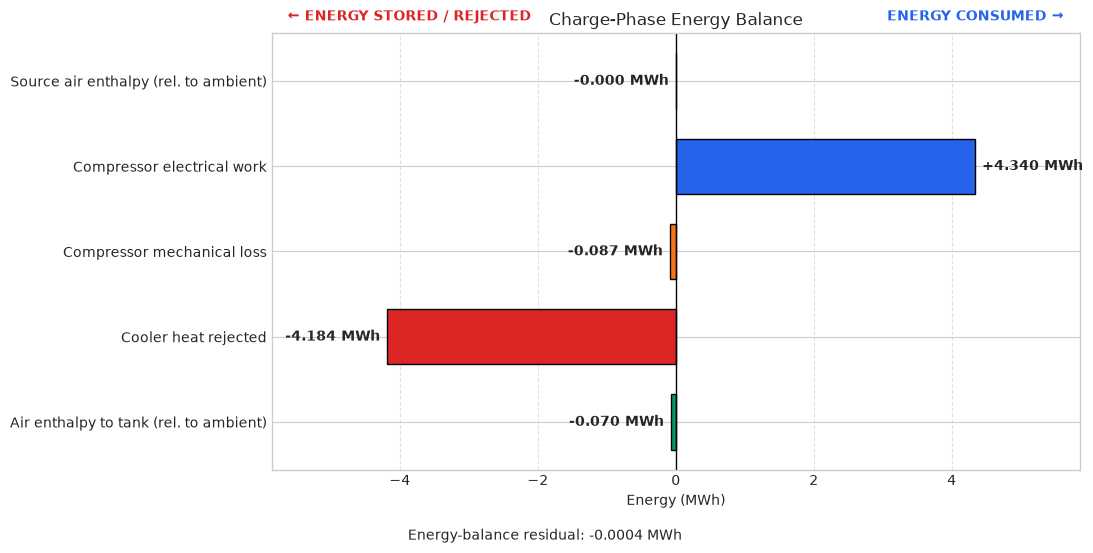

In [173]:
# ==============================================================================
# Charge Phase Energy Balance (Fixed & Referenced to Ambient)
# ==============================================================================
time = results_charge.time
J_PER_MWH = 3.6e9

# Ambient reference specific enthalpy for air [J/kg] at (T0, P0)
h0_air = PropsSI("H", "T", T0, "P", P0, "Air")

# 1. ENERGY INPUTS (Consumed -> Positive)
# Source air enthalpy relative to ambient (0 MWh since T_source = T0, P_source = P0)
H_source_rate_W = (
    np.abs(results_charge.Source_Charge.port.mdot)
    * (results_charge.Source_Charge.port.h - h0_air)
)
H_source_MWh = np.trapezoid(H_source_rate_W, x=time) / J_PER_MWH

# Compressor fluid work (Wdot is negative in caldis, so take abs for input)
W_comp_fluid_J = np.trapezoid(np.abs(results_charge.Comp_Charge.Wdot), x=time)
W_comp_fluid_MWh = W_comp_fluid_J / J_PER_MWH

# Total electrical work consumed from grid (accounting for Eta_Mech = 0.98)
W_comp_elec_MWh = W_comp_fluid_MWh / Eta_Mech

# 2. ENERGY OUTPUTS / LOSSES (Stored or Rejected -> Negative)
# Compressor mechanical / motor loss (2%)
comp_mech_loss_MWh = W_comp_elec_MWh - W_comp_fluid_MWh

# Heat rejected in the water aftercooler
Q_cooler_MWh = np.trapezoid(results_charge.Hex_Charge.Qdot, x=time) / J_PER_MWH

# Net air enthalpy transferred into the tank, relative to ambient h0
H_tank_in_rate_W = (
    np.abs(results_charge.Tank_Charge.fluid.inl.mdot)
    * (results_charge.Tank_Charge.fluid.inl.h - h0_air)
)
H_tank_in_MWh = np.trapezoid(H_tank_in_rate_W, x=time) / J_PER_MWH

# Inputs are positive; outputs/losses are negative (matching Discharge plot)
energy_labels = [
    "Source air enthalpy (rel. to ambient)",
    "Compressor electrical work",
    "Compressor mechanical loss",
    "Cooler heat rejected",
    "Air enthalpy to tank (rel. to ambient)",
]
energy_values = [
    H_source_MWh,
    W_comp_elec_MWh,
    -comp_mech_loss_MWh,
    -Q_cooler_MWh,
    -H_tank_in_MWh,
]
energy_colors = ["#94a3b8", "#2563eb", "#f97316", "#dc2626", "#059669"]

energy_residual_MWh = sum(energy_values)

# ==============================================================================
# Charge Phase Energy Balance Plot
# ==============================================================================
fig, ax = plt.subplots(figsize=(11, 5.5))

bars = ax.barh(
    energy_labels,
    energy_values,
    color=energy_colors,
    edgecolor="black",
    height=0.65,
)

ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Energy (MWh)")
ax.set_title("Charge-Phase Energy Balance")
ax.grid(axis="x", linestyle="--", alpha=0.6)
ax.set_axisbelow(True)
ax.invert_yaxis()

max_value = max(abs(value) for value in energy_values)
limit = max_value * 1.35 if max_value > 0 else 1
ax.set_xlim(-limit, limit)

ax.text(
    0.02, 1.03, "← ENERGY STORED / REJECTED",
    transform=ax.transAxes,
    color="#dc2626",
    fontweight="bold",
)
ax.text(
    0.98, 1.03, "ENERGY CONSUMED →",
    transform=ax.transAxes,
    color="#2563eb",
    fontweight="bold",
    ha="right",
)

for bar, value in zip(bars, energy_values):
    ax.annotate(
        f"{value:+.3f} MWh",
        xy=(value, bar.get_y() + bar.get_height() / 2),
        xytext=(5 if value >= 0 else -5, 0),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center",
        fontweight="bold",
    )

fig.text(
    0.5, 0.01,
    f"Energy-balance residual: {energy_residual_MWh:.4f} MWh",
    ha="center",
)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

In [174]:
# ==============================================================================
# Charge Phase Exergy Balance
# ==============================================================================
# T0 must be in K and P0 in Pa. Exergy rates are in W; integrated values are MWh.

time = results_charge.time

def flow_exergy_rate(mdot, p, h, fluid):
    """Flow exergy rate [W] for the recorded time series."""
    h0 = PropsSI("H", "T", T0, "P", P0, fluid)
    s0 = PropsSI("S", "T", T0, "P", P0, fluid)
    s = PropsSI("S", "P", p, "H", h, fluid)

    specific_exergy = (h - h0) - T0 * (s - s0)
    return np.abs(mdot) * specific_exergy


# Exergy entering with source air
X_source_W = flow_exergy_rate(
    results_charge.Source_Charge.port.mdot,
    results_charge.Source_Charge.port.p,
    results_charge.Source_Charge.port.h,
    "Air",
)

# Compressor inlet and outlet exergy rates
X_comp_in_W = flow_exergy_rate(
    results_charge.Comp_Charge.inl.mdot,
    results_charge.Comp_Charge.inl.p,
    results_charge.Comp_Charge.inl.h,
    "Air",
)
X_comp_out_W = flow_exergy_rate(
    results_charge.Comp_Charge.out.mdot,
    results_charge.Comp_Charge.out.p,
    results_charge.Comp_Charge.out.h,
    "Air",
)

# Aftercooler hot-side (air) and cold-side (cooling water) exergy rates
X_hot_in_W = flow_exergy_rate(
    results_charge.Hex_Charge.hot_in.mdot,
    results_charge.Hex_Charge.hot_in.p,
    results_charge.Hex_Charge.hot_in.h,
    "Air",
)
X_hot_out_W = flow_exergy_rate(
    results_charge.Hex_Charge.hot_out.mdot,
    results_charge.Hex_Charge.hot_out.p,
    results_charge.Hex_Charge.hot_out.h,
    "Air",
)
X_cold_in_W = flow_exergy_rate(
    results_charge.Hex_Charge.cold_in.mdot,
    results_charge.Hex_Charge.cold_in.p,
    results_charge.Hex_Charge.cold_in.h,
    "Water",
)
X_cold_out_W = flow_exergy_rate(
    results_charge.Hex_Charge.cold_out.mdot,
    results_charge.Hex_Charge.cold_out.p,
    results_charge.Hex_Charge.cold_out.h,
    "Water",
)

# Exergy transferred with the air entering the tank
X_tank_in_W = flow_exergy_rate(
    results_charge.Tank_Charge.fluid.inl.mdot,
    results_charge.Tank_Charge.fluid.inl.p,
    results_charge.Tank_Charge.fluid.inl.h,
    "Air",
)

# Exergy entering the charge system
X_source_MWh = np.trapezoid(X_source_W, x=time) / 3.6e9
X_comp_work_MWh = np.trapezoid(results_charge.Comp_Charge.Wdot, x=time) / 3.6e9

# Exergy leaving the charge system with tank-bound air and warmed cooling water
X_tank_in_MWh = np.trapezoid(X_tank_in_W, x=time) / 3.6e9
X_coolant_gain_MWh = np.trapezoid(X_cold_out_W - X_cold_in_W, x=time) / 3.6e9

# Component exergy destruction
X_comp_destroyed_MWh = np.trapezoid( -results_charge.Comp_Charge.Wdot + X_comp_in_W - X_comp_out_W, x=time,) / 3.6e9

X_cooler_destroyed_MWh = np.trapezoid(X_hot_in_W - X_hot_out_W - (X_cold_out_W - X_cold_in_W), x=time,) / 3.6e9

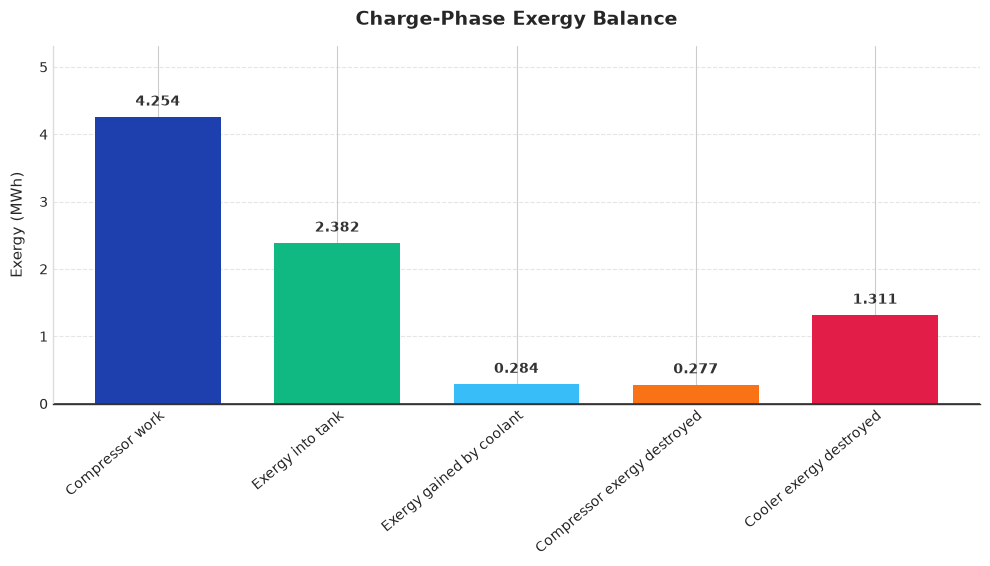

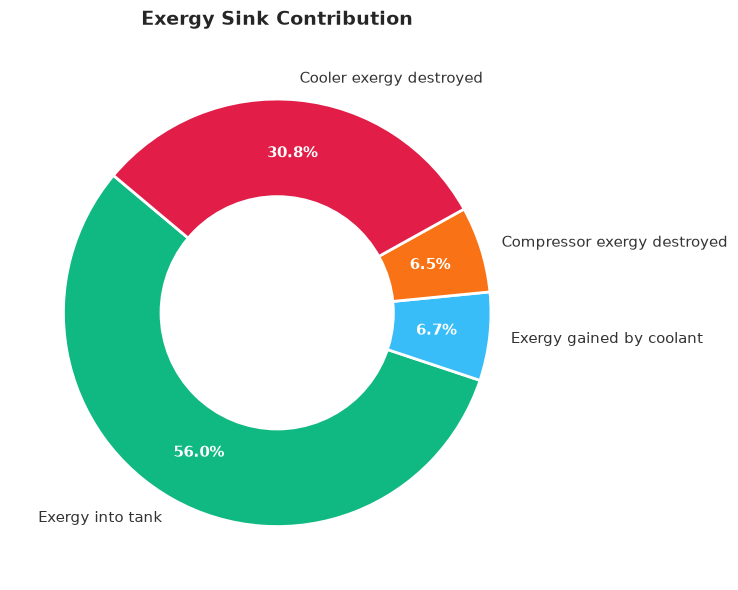

In [175]:
import matplotlib.pyplot as plt
import numpy as np

# Charge-phase exergy balance plot
exergy_labels = ["Compressor work", "Exergy into tank", "Exergy gained by coolant", "Compressor exergy destroyed", "Cooler exergy destroyed"]

exergy_values = [X_comp_work_MWh, X_tank_in_MWh, X_coolant_gain_MWh, X_comp_destroyed_MWh, X_cooler_destroyed_MWh]

# Updated colors: removed grey since "Source air exergy" was removed from labels
exergy_colors = ["#1e40af", "#10b981", "#38bdf8", "#f97316", "#e11d48"]

# Ensure all values are positive for the upward bar chart
exergy_values_abs = [abs(val) for val in exergy_values]

plt.style.use('seaborn-v0_8-whitegrid')

# ==========================================
# FIGURE 1: Bar Chart
# ==========================================
fig1, ax1 = plt.subplots(figsize=(10, 6))

bars = ax1.bar(exergy_labels, exergy_values_abs, color=exergy_colors, edgecolor="none", width=0.7)

ax1.axhline(0, color="#333333", linewidth=1.2)
ax1.set_ylabel("Exergy (MWh)", fontsize=11, labelpad=10)
ax1.set_title("Charge-Phase Exergy Balance", fontsize=14, fontweight="bold", pad=15)
ax1.grid(axis="y", linestyle="--", alpha=0.5, color="#cccccc")
ax1.set_axisbelow(True)

# Remove top and right spines
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_color('#dddddd')
ax1.spines['bottom'].set_color('#333333')

# Improve x-axis label alignment
ax1.set_xticks(range(len(exergy_labels)))
ax1.set_xticklabels(exergy_labels, rotation=40, ha='right', fontsize=10, rotation_mode='anchor')

# Adjust y-limits to start at 0
max_value = max(exergy_values_abs)
limit = max_value * 1.25 if max_value > 0 else 1
ax1.set_ylim(0, limit)

# Simplified upward bar annotations
for bar, value in zip(bars, exergy_values_abs):
    ax1.annotate(
        f"{value:.3f}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#333333"
    )

fig1.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

# ==========================================
# FIGURE 2: Exergy Sink Contribution
# ==========================================
# Extract only the sink/output values (ignoring the Compressor work input at index 0)
out_labels = exergy_labels[1:]
out_values = exergy_values_abs[1:]
out_colors = exergy_colors[1:]

fig2, ax2 = plt.subplots(figsize=(8, 6))

wedges, texts, autotexts = ax2.pie(
    out_values, 
    labels=out_labels, 
    colors=out_colors, 
    autopct='%1.1f%%', 
    startangle=140, 
    pctdistance=0.75,
    textprops={'fontsize': 11, 'color': '#333333'},
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

# Convert pie to a donut chart
centre_circle = plt.Circle((0,0), 0.55, fc='white')
ax2.add_artist(centre_circle)

ax2.set_title("Exergy Sink Contribution", fontsize=14, fontweight="bold", pad=15)

# Style the percentage text inside the donut
for autotext in autotexts:
    autotext.set_fontweight('bold')
    autotext.set_color('white')

fig2.tight_layout()
plt.show()

## 5.2 Discharge Phase

In [176]:
Comb.describe()

=== CombustionChamber('Comb') ===
  ports (p [bar], mdot [kg/s], T [°C]):
    air_in     p=16.000  mdot=+2.511  h=399.8kJ/kg  T=4.40
    fuel_in    p=1.013  mdot=+0.0292  h=887.7kJ/kg  T=15.00
    gas_out    p=15.360  mdot=-2.54  h=974.4kJ/kg  T=550.00
  outputs:
    Qdot_fuel        = 1.45976e+06
    Qdot_released    = 1.45976e+06
    AFR              = 86.0142
    excess_air       = 5.00082


{'variables': {},
 'ports': {'air_in': {'p': 1600000.0,
   'mdot': 2.5111978294317976,
   'h': 399781.1880585189},
  'fuel_in': {'p': 101300.0,
   'mdot': 0.029195168367007262,
   'h': 887746.0468104853},
  'gas_out': {'p': 1536000.0,
   'mdot': -2.5403929977988047,
   'h': 974428.4572724903}},
 'outputs': {'Qdot_fuel': 1459758.4183503632,
  'Qdot_released': 1459758.4183503632,
  'AFR': 86.01415816014406,
  'excess_air': 5.000823148845585}}

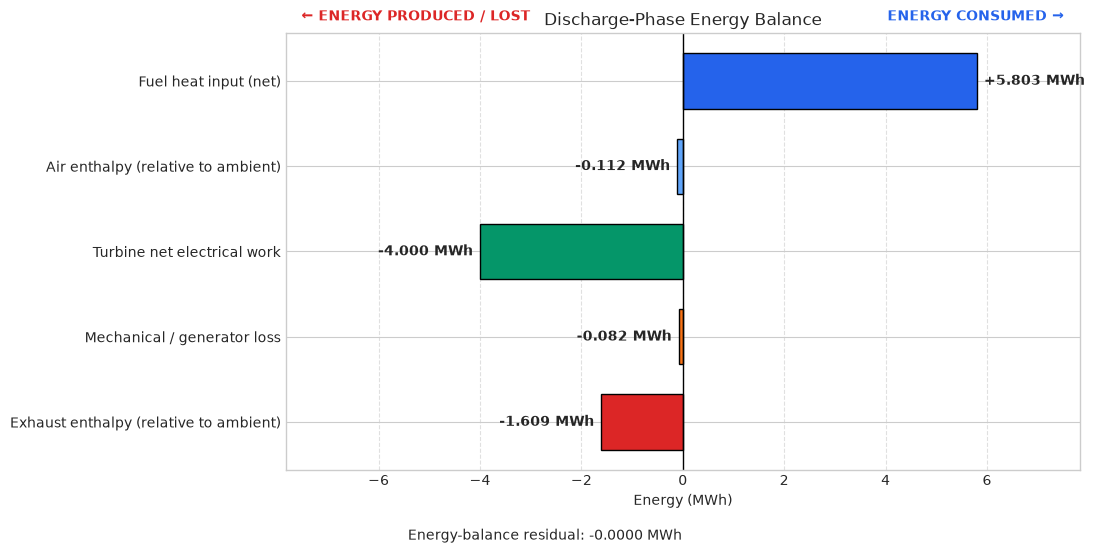

In [177]:
# ==============================================================================
# Discharge Phase Energy Balance (Fixed)
# ==============================================================================
time = results_discharge.time
J_PER_MWH = 3.6e9

# Ambient reference specific enthalpy for air [J/kg] at (T0, P0)
h0_air = PropsSI("H", "T", T0, "P", P0, "Air")

# 1. ENERGY INPUTS (Consumed)
# Fuel chemical heat input (LHV)
fuel_energy_MWh = np.trapezoid(
    results_discharge.Comb.Qdot_fuel,
    x=time,
) / J_PER_MWH

# Air enthalpy entering the combustor, relative to ambient h0
# (Slightly negative because tank air cools below T0 and is at 16 bar)
air_enthalpy_rate_W = (
    np.abs(results_discharge.Comb.air_in.mdot)
    * (results_discharge.Comb.air_in.h - h0_air)
)
air_enthalpy_MWh = np.trapezoid(air_enthalpy_rate_W, x=time) / J_PER_MWH

# Fuel sensible enthalpy offset in Combustor relative to h0
# Accounts for fuel mass addition and T_fuel (15 °C) vs LHV reference T_ref (25 °C)
comb_gas_out_rate_W = (
    np.abs(results_discharge.Comb.gas_out.mdot)
    * (results_discharge.Comb.gas_out.h - h0_air)
)
fuel_sensible_rate_W = (
    comb_gas_out_rate_W - air_enthalpy_rate_W - results_discharge.Comb.Qdot_fuel
)
fuel_sensible_MWh = np.trapezoid(fuel_sensible_rate_W, x=time) / J_PER_MWH

# Total net combustor thermal input (LHV + fuel sensible offset)
net_fuel_energy_MWh = fuel_energy_MWh + fuel_sensible_MWh

# 2. ENERGY OUTPUTS / LOSSES (Produced / Lost)
# Turbine net electrical / shaft work delivered (after Eta_Mech = 0.98)
turbine_energy_MWh = np.trapezoid(
    results_discharge.turbine.Wdot,
    x=time,
) / J_PER_MWH

# Mechanical / generator shaft loss: Wdot_loss = Wdot_net * (1 - Eta_Mech) / Eta_Mech
mech_loss_rate_W = results_discharge.turbine.Wdot * ((1.0 - Eta_Mech) / Eta_Mech)
mech_loss_MWh = np.trapezoid(mech_loss_rate_W, x=time) / J_PER_MWH

# Exhaust enthalpy leaving the turbine, relative to ambient h0
exhaust_enthalpy_rate_W = (
    np.abs(results_discharge.turbine.out.mdot)
    * (results_discharge.turbine.out.h - h0_air)
)
exhaust_energy_MWh = np.trapezoid(
    exhaust_enthalpy_rate_W,
    x=time,
) / J_PER_MWH

# Inputs are positive; outputs/losses are negative for plotting
energy_labels = [
    "Fuel heat input (net)",
    "Air enthalpy (relative to ambient)",
    "Turbine net electrical work",
    "Mechanical / generator loss",
    "Exhaust enthalpy (relative to ambient)",
]
energy_values = [
    net_fuel_energy_MWh,
    air_enthalpy_MWh,
    -turbine_energy_MWh,
    -mech_loss_MWh,
    -exhaust_energy_MWh,
]
energy_colors = ["#2563eb", "#60a5fa", "#059669", "#f97316", "#dc2626"]

energy_residual_MWh = sum(energy_values)

# ==============================================================================
# Discharge Phase Energy Balance Plot
# ==============================================================================
fig, ax = plt.subplots(figsize=(11, 5.5))

bars = ax.barh(
    energy_labels,
    energy_values,
    color=energy_colors,
    edgecolor="black",
    height=0.65,
)

ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Energy (MWh)")
ax.set_title("Discharge-Phase Energy Balance")
ax.grid(axis="x", linestyle="--", alpha=0.6)
ax.set_axisbelow(True)
ax.invert_yaxis()

max_value = max(abs(value) for value in energy_values)
limit = max_value * 1.35 if max_value > 0 else 1
ax.set_xlim(-limit, limit)

ax.text(
    0.02, 1.03, "← ENERGY PRODUCED / LOST",
    transform=ax.transAxes,
    color="#dc2626",
    fontweight="bold",
)
ax.text(
    0.98, 1.03, "ENERGY CONSUMED →",
    transform=ax.transAxes,
    color="#2563eb",
    fontweight="bold",
    ha="right",
)

for bar, value in zip(bars, energy_values):
    ax.annotate(
        f"{value:+.3f} MWh",
        xy=(value, bar.get_y() + bar.get_height() / 2),
        xytext=(5 if value >= 0 else -5, 0),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center",
        fontweight="bold",
    )

fig.text(
    0.5, 0.01,
    f"Energy-balance residual: {energy_residual_MWh:.4f} MWh",
    ha="center",
)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

In [178]:
# ==============================================================================
# Discharge Phase Exergy Balance
# ==============================================================================
# T0 must be in K and P0 in Pa. Exergy rates are in W; integrated values are MWh.

time = results_discharge.time

# Exergy entering combustor with air from the storage tank
X_air_in_W = flow_exergy_rate(
    results_discharge.Comb.air_in.mdot,
    results_discharge.Comb.air_in.p,
    results_discharge.Comb.air_in.h,
    "Air",
)

# Chemical exergy entering with fuel (estimated as 1.04 x fuel LHV heat rate)
X_fuel_in_W = 1.04 * results_discharge.Comb.Qdot_fuel

# Combustor outlet / Turbine inlet exergy rate
X_turb_in_W = flow_exergy_rate(
    results_discharge.turbine.inl.mdot,
    results_discharge.turbine.inl.p,
    results_discharge.turbine.inl.h,
    "Air",
)

# Turbine exhaust exergy rate leaving to ambient
X_exhaust_W = flow_exergy_rate(
    results_discharge.turbine.out.mdot,
    results_discharge.turbine.out.p,
    results_discharge.turbine.out.h,
    "Air",
)

# Turbine delivered electrical / shaft power rate
X_turb_work_W = results_discharge.turbine.Wdot

# Integrate exergy rates over the discharge duration [MWh]
X_air_in_MWh = np.trapezoid(X_air_in_W, x=time) / 3.6e9
X_fuel_in_MWh = np.trapezoid(X_fuel_in_W, x=time) / 3.6e9
X_total_input_MWh = X_fuel_in_MWh + X_air_in_MWh

X_turb_in_MWh = np.trapezoid(X_turb_in_W, x=time) / 3.6e9
X_turb_work_MWh = np.trapezoid(X_turb_work_W, x=time) / 3.6e9
X_exhaust_loss_MWh = np.trapezoid(X_exhaust_W, x=time) / 3.6e9

# Component exergy destructions
X_comb_destroyed_MWh = np.trapezoid(X_air_in_W + X_fuel_in_W - X_turb_in_W, x=time) / 3.6e9
X_turb_destroyed_MWh = np.trapezoid(X_turb_in_W - X_exhaust_W - X_turb_work_W, x=time) / 3.6e9

# Balance check; strictly closes to 0
X_balance_residual_MWh = (
    X_total_input_MWh
    - X_turb_work_MWh
    - X_exhaust_loss_MWh
    - X_comb_destroyed_MWh
    - X_turb_destroyed_MWh
)

# Summary table compatibility variables
exergy_input_MWh = X_total_input_MWh
turbine_work_exergy_MWh = X_turb_work_MWh
combustor_exergy_destruction_MWh = X_comb_destroyed_MWh
turbine_exergy_destruction_MWh = X_turb_destroyed_MWh
exhaust_exergy_MWh = X_exhaust_loss_MWh
exergy_balance_residual_MWh = X_balance_residual_MWh

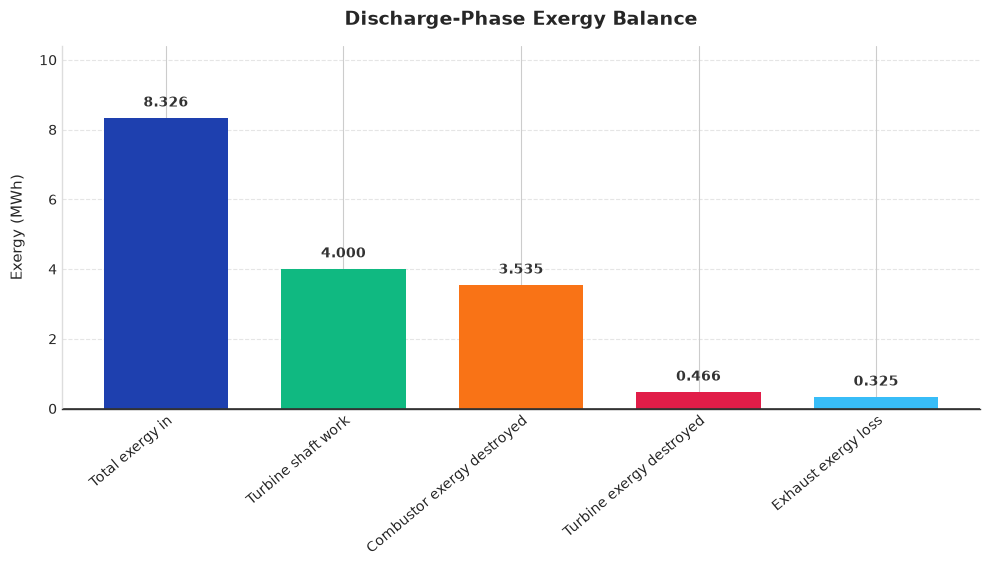

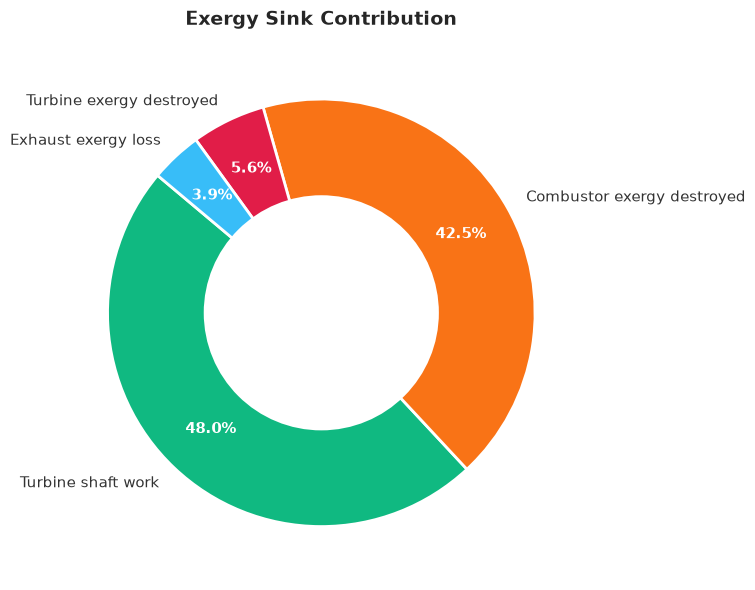

In [179]:
import matplotlib.pyplot as plt
import numpy as np

# Discharge-phase exergy balance plot
exergy_labels = [
    "Total exergy in",
    "Turbine shaft work",
    "Combustor exergy destroyed",
    "Turbine exergy destroyed",
    "Exhaust exergy loss",
]

exergy_values = [
    X_total_input_MWh,
    X_turb_work_MWh,
    X_comb_destroyed_MWh,
    X_turb_destroyed_MWh,
    X_exhaust_loss_MWh,
]

# Color palette aligned with charge:
# Blue for input (#1e40af), Green for useful output (#10b981),
# Orange/Red for destructions (#f97316, #e11d48), Sky blue for exhaust flow loss (#38bdf8)
exergy_colors = ["#1e40af", "#10b981", "#f97316", "#e11d48", "#38bdf8"]

exergy_values_abs = [abs(val) for val in exergy_values]

plt.style.use('seaborn-v0_8-whitegrid')

# ==========================================
# FIGURE 1: Bar Chart
# ==========================================
fig1, ax1 = plt.subplots(figsize=(10, 6))

bars = ax1.bar(exergy_labels, exergy_values_abs, color=exergy_colors, edgecolor="none", width=0.7)

ax1.axhline(0, color="#333333", linewidth=1.2)
ax1.set_ylabel("Exergy (MWh)", fontsize=11, labelpad=10)
ax1.set_title("Discharge-Phase Exergy Balance", fontsize=14, fontweight="bold", pad=15)
ax1.grid(axis="y", linestyle="--", alpha=0.5, color="#cccccc")
ax1.set_axisbelow(True)

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_color('#dddddd')
ax1.spines['bottom'].set_color('#333333')

ax1.set_xticks(range(len(exergy_labels)))
ax1.set_xticklabels(exergy_labels, rotation=40, ha='right', fontsize=10, rotation_mode='anchor')

max_value = max(exergy_values_abs)
limit = max_value * 1.25 if max_value > 0 else 1
ax1.set_ylim(0, limit)

for bar, value in zip(bars, exergy_values_abs):
    ax1.annotate(
        f"{value:.3f}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#333333"
    )

fig1.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

# ==========================================
# FIGURE 2: Exergy Sink Contribution
# ==========================================
out_labels = exergy_labels[1:]
out_values = exergy_values_abs[1:]
out_colors = exergy_colors[1:]

fig2, ax2 = plt.subplots(figsize=(8, 6))

wedges, texts, autotexts = ax2.pie(
    out_values, 
    labels=out_labels, 
    colors=out_colors, 
    autopct='%1.1f%%', 
    startangle=140, 
    pctdistance=0.75,
    textprops={'fontsize': 11, 'color': '#333333'},
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

centre_circle = plt.Circle((0,0), 0.55, fc='white')
ax2.add_artist(centre_circle)

ax2.set_title("Exergy Sink Contribution", fontsize=14, fontweight="bold", pad=15)

for autotext in autotexts:
    autotext.set_fontweight('bold')
    autotext.set_color('white')

fig2.tight_layout()
plt.show()

## 5.3 Charge & DisCharge Summary Tables

In [185]:
charge_summary_data = [
    ("Charge duration", f"{t_charge / 3600:.1f}", "h"),
    ("Ambient inlet temperature", f"{T0 - 273.15:.1f}", "°C"),
    ("Ambient inlet pressure", f"{P0 / 1e5:.3f}", "bar"),
    ("Storage pressure", f"{Pmax / 1e5:.1f}", "bar"),
    ("Air mass flow rate", f"{Mdot_charge:.4f}", "kg/s"),
    ("Compressor isentropic efficiency", f"{Eta_ISC * 100:.1f}", "%"),
    ("Compressor outlet temperature", f"{Comp_Charge.out.T - 273.15:.1f}", "°C"),
    ("Mean compressor power", f"{wdot_comp_MW:.3f}", "MW"),
    ("Compressor energy used", f"{w_comp_MWh:.3f}", "MWh"),
    ("Cooler outlet air target", f"{T_cooler_out - 273.15:.1f}", "°C"),
    ("Cooling-water mass flow rate", f"{Mdot_water:.2f}", "kg/s"),
    ("Cooling-water inlet temperature", f"{T_water_in - 273.15:.1f}", "°C"),
    ("Cooling-water outlet temperature", f"{be_water.T(Hex_Charge.cold_out.p, Hex_Charge.cold_out.h) - 273.15:.1f}", "°C"),
    ("Air-side heat-transfer coefficient", f"{h_film_air:.1f}", "W/(m²·K)"),
    ("Water-side heat-transfer coefficient", f"{h_film_water:.1f}", "W/(m²·K)"),
    ("Cooler cold/hot area ratio", f"{Ratio_Area_cold_to_hot:.4f}", "-"),
    ("Cooler air-side area (A_air)", f"{A_air_cooler:.1f}", "m²"),
    ("Cooler conductance (UA)", f"{Hex_Charge.UA:.1f}", "W/K"),
    ("Cooler heat rejected", f"{q_cooler_MWh:.3f}", "MWh"),
    ("Air mass added to tank", f"{m_air_added_sim:.1f}", "kg"),
    ("Tank volume at start / end", f"{V_tank_initial_sim:.1f} / {V_charged:.1f}", "m³"),
    ("Final tank air temperature", f"{T_tank_final_sim - 273.15:.1f}", "°C"),
    ("Final tank pressure", f"{P_tank_final_sim / 1e5:.2f}", "bar"),
    ("Tank wall heat capacity", f"{Cwall / 1e6:.2f}", "MJ/K"),
    ("Tank wall conductance (UA)", f"{UA_wall:.1f}", "W/K"),
    ("Exergy stored in tank air", f"{exergy_stored_MWh:.3f}", "MWh"),
    ("Compressor exergy destruction", f"{exergy_destroyed_comp_MWh:.3f}", "MWh"),
    ("Aftercooler exergy destruction", f"{exergy_destroyed_cooler_MWh:.3f}", "MWh"),
]


discharge_summary_data = [
    ("Discharge duration", f"{t_discharge / 3600:.1f}", "h"),
    ("Storage pressure", f"{Pmax / 1e5:.1f}", "bar"),
    ("Initial tank air temperature", f"{T0 - 273.15:.1f}", "°C"),
    ("Turbine inlet temperature target", f"{Ttit - 273.15:.1f}", "°C"),
    ("Combustor pressure drop", f"{dp_comb_rel * 100:.1f}", "%"),
    ("Turbine isentropic efficiency", f"{Eta_IST * 100:.1f}", "%"),
    ("Mechanical / generator efficiency", f"{Eta_Mech * 100:.1f}", "%"),
    ("Target turbine power", f"{W_target / 1e6:.2f}", "MW"),
    ("Average simulated turbine power", f"{shaft_power_mean / 1e6:.3f}", "MW"),
    ("Turbine energy delivered", f"{turbine_energy_MWh:.3f}", "MWh"),
    ("Design air mass flow rate", f"{Mdot_discharge:.4f}", "kg/s"),
    ("Average simulated air flow rate", f"{air_flow_mean_dis:.4f}", "kg/s"),
    ("Average simulated fuel flow rate", f"{fuel_flow_mean_dis:.5f}", "kg/s"),
    ("Fuel heating value", f"{Comb.params['LHV'] / 1e6:.1f}", "MJ/kg"),
    ("Combustion heat supplied", f"{q_fuel_MWh:.3f}", "MWh"),
    ("Air mass discharged", f"{air_mass_kg:.1f}", "kg"),
    ("Fuel mass consumed", f"{fuel_mass_kg:.1f}", "kg"),
    ("Tank volume at start / end", f"{V_discharge_sized:.1f} / {V_discharge_final:.3f}", "m³"),
    ("Tank shell outer diameter", f"{Diameter_Tank_out:.2f}", "m"),
    ("Tank wall thickness", f"{Thickness_wall:.3f}", "m"),
    ("Tank wall heat capacity", f"{Cwall / 1e6:.2f}", "MJ/K"),
    ("Tank wall conductance (UA)", f"{UA_wall:.1f}", "W/K"),
    ("Exhaust energy", f"{exhaust_loss_MWh:.3f}", "MWh"),
    ("Mechanical loss", f"{mech_loss_MWh:.3f}", "MWh"),
    ("Overall round-trip efficiency", f"{round_trip_efficiency * 100:.2f}", "%"),
    ("Fuel electric-equivalent share", f"{fuel_share:.1f}", "%"),
    ("Exergy entering discharge cycle", f"{exergy_input_MWh:.3f}", "MWh"),
    ("Combustor exergy destruction", f"{combustor_exergy_destruction_MWh:.3f}", "MWh"),
    ("Turbine exergy destruction", f"{turbine_exergy_destruction_MWh:.3f}", "MWh"),
    ("Exhaust exergy", f"{exhaust_exergy_MWh:.3f}", "MWh"),
    ("Exergy balance residual", f"{exergy_balance_residual_MWh:.6f}", "MWh"),
]
df_discharge_overview = pd.DataFrame(discharge_summary_data, columns=["Discharge-phase parameter", "Value", "Unit"])
print("DISCHARGE PHASE SUMMARY")
display(df_discharge_overview)

CHARGE PHASE SUMMARY


,Charge-phase parameter,Value,Unit
0,Charge duration,4.0,h
1,Ambient inlet temperature,15.0,°C
2,Ambient inlet pressure,1.013,bar
3,Storage pressure,16.0,bar
4,Air mass flow rate,2.6122,kg/s
5,Compressor isentropic efficiency,85.0,%
6,Compressor outlet temperature,410.6,°C
7,Mean compressor power,-15312.639,MW
8,Compressor energy used,-4.254,MWh
9,Cooler outlet air target,25.0,°C


DISCHARGE PHASE SUMMARY


,Discharge-phase parameter,Value,Unit
0,Discharge duration,4.0,h
1,Storage pressure,16.0,bar
2,Initial tank air temperature,15.0,°C
3,Turbine inlet temperature target,550.0,°C
4,Combustor pressure drop,4.0,%
5,Turbine isentropic efficiency,88.0,%
6,Mechanical / generator efficiency,98.0,%
7,Target turbine power,1.00,MW
8,Average simulated turbine power,1.000,MW
9,Turbine energy delivered,4.000,MWh


In [182]:
# ==============================================================================
# Variant 1b Master Summary Table: All PDF Specifications & Deliverables
# ==============================================================================
import pandas as pd
import numpy as np

# ------------------------------------------------------------------------------
# 1. Extract / Calculate Values from Notebook Scope with Safe Fallbacks
# ------------------------------------------------------------------------------
# Reference Conditions & Fixed Targets (PDF Section 3)
p0_bar = globals().get('P0', 1.013e5) / 1e5
t0_c = globals().get('T0', 288.15) - 273.15
pmax_bar = globals().get('Pmax', 16.0e5) / 1e5
t_dis_h = globals().get('t_discharge', 4.0 * 3600.0) / 3600.0
t_ch_h = globals().get('t_charge', 4.0 * 3600.0) / 3600.0
target_w_mw = globals().get('W_target', 1.0e6) / 1e6
eta_fc = globals().get('Eta_ISC', 0.85) * 100.0
eta_ft = globals().get('Eta_IST', 0.88) * 100.0
eta_fm = globals().get('Eta_Mech', 0.98) * 100.0
eta_ff = globals().get('Eta_Fuel', 0.40)
tit_c = globals().get('Ttit', 823.15) - 273.15
pinch_k = globals().get('T_pinch', 10.0)

# Deliverables & Comparison Criteria (PDF Section 3 & 5)
w_turb_val = globals().get('turbine_energy_MWh', globals().get('w_turb_MWh', globals().get('W_turb_MWh', 4.000)))
w_comp_val = globals().get('w_comp_MWh', globals().get('W_comp_MWh', 4.254))
q_fuel_val = globals().get('q_fuel_MWh', globals().get('Q_fuel_MWh', 5.804))
q_cooler_val = globals().get('q_cooler_MWh', globals().get('Q_cooler_MWh', 4.174))

# Weighted Input & Round-Trip Efficiency (PDF Eq: eta = W_turb / (W_comp + eta_f * Q_fuel))
w_fuel_eq_val = eta_ff * q_fuel_val
w_in_total_val = w_comp_val + w_fuel_eq_val
rt_eff_val = (w_turb_val / w_in_total_val) * 100.0
elec_pct_val = (w_comp_val / w_in_total_val) * 100.0
fuel_pct_val = (w_fuel_eq_val / w_in_total_val) * 100.0

# Storage Sizing (PDF Section 3: "max variable volume at warmest state / end of charge")
v_max_charged = globals().get('V_charged', 2015.5)
v_dis_start = globals().get('V_discharge_sized', globals().get('V_start', 1858.2))
m_air_kg = globals().get('air_mass_kg', 36163.7)
m_fuel_kg = globals().get('fuel_mass_kg', 417.9)

# Heat-Exchanger Sizing (PDF Section 3: "compared as the air-side area A_air")
a_air_m2 = globals().get('A_air_cooler', 380.6)
a_water_m2 = a_air_m2 / 15.0
ua_cooler = getattr(globals().get('Hex_Charge', None), 'UA', 10875.7)

# Temperatures Reached (PDF Section 3)
t_comp_out_c = globals().get('Comp_Charge').out.T - 273.15 if 'Comp_Charge' in globals() else 410.6
t_cooler_out_c = t0_c + pinch_k

# Flow Rates
mdot_ch_val = globals().get('Mdot_charge', m_air_kg / (t_ch_h * 3600.0))
mdot_dis_val = globals().get('air_flow_mean_dis', globals().get('Mdot_discharge', 2.5114))
mdot_fuel_val = globals().get('fuel_flow_mean_dis', 0.0290)
mdot_water_val = globals().get('Mdot_water', 6.00)

# Thermal & Mechanical Losses
exhaust_loss_val = globals().get('exhaust_loss_MWh', 1.609)
mech_loss_val = globals().get('mech_loss_MWh', 0.082)

# Exergy Metrics (PDF Section 5 Deliverables)
x_in_val = globals().get('X_total_input_MWh', globals().get('exergy_input_MWh', 8.326))
x_work_val = globals().get('X_turb_work_MWh', globals().get('turbine_work_exergy_MWh', 4.000))
x_comb_dest = globals().get('X_comb_destroyed_MWh', globals().get('combustor_exergy_destruction_MWh', 3.535))
x_turb_dest = globals().get('X_turb_destroyed_MWh', globals().get('turbine_exergy_destruction_MWh', 0.466))
x_comp_dest = globals().get('X_comp_destroyed_MWh', globals().get('exergy_destroyed_comp_MWh', 0.283))
x_cooler_dest = globals().get('X_cooler_destroyed_MWh', globals().get('exergy_destroyed_cooler_MWh', 1.589))
x_exhaust_dest = globals().get('X_exhaust_loss_MWh', globals().get('exhaust_exergy_MWh', 0.325))
x_residual = globals().get('X_balance_residual_MWh', globals().get('exergy_balance_residual_MWh', 0.0))

# ------------------------------------------------------------------------------
# 2. Build Structured Master DataFrame
# ------------------------------------------------------------------------------
master_data = [
    # --- 1. CORE COMPARISON CRITERIA (PDF Section 3 & 5) ---
    ("1. Comparison Criteria", "Overall Round-Trip Efficiency", "η = W_turb / (W_comp + η_f · Q_fuel)", f"{rt_eff_val:.2f}", "%"),
    ("1. Comparison Criteria", "Required Storage Volume (End of Charge)", "V_storage,max (evaluated at warmest state)", f"{v_max_charged:,.1f}", "m³"),
    ("1. Comparison Criteria", "Dimensioning Cooler Area (Air-side)", "A_air (governing heat-transfer surface)", f"{a_air_m2:.1f}", "m²"),
    ("1. Comparison Criteria", "Electrical Input Share", "W_comp / (W_comp + η_f · Q_fuel)", f"{elec_pct_val:.1f}", "%"),
    ("1. Comparison Criteria", "Fuel Input Share (Electric-Equivalent)", "(η_f · Q_fuel) / (W_comp + η_f · Q_fuel)", f"{fuel_pct_val:.1f}", "%"),
    ("1. Comparison Criteria", "Peak Compressor Discharge Temperature", "T_comp,out (maximum compression temp)", f"{t_comp_out_c:.1f}", "°C"),
    ("1. Comparison Criteria", "Turbine Inlet Temperature (TIT)", "TIT (reached via direct combustion)", f"{tit_c:.1f}", "°C"),

    # --- 2. SYSTEM SIZING & DESIGN MODE (PDF Section 2 & 3) ---
    ("2. Design Mode Sizing", "Working Fluid", "CoolProp real-gas equation of state", "Air", "-"),
    ("2. Design Mode Sizing", "Constant Storage Pressure", "P_storage = P_max (isobaric reservoir)", f"{pmax_bar:.1f}", "bar"),
    ("2. Design Mode Sizing", "Discharged Storage Volume (15 °C)", "V_dis,start (at ambient reference T0)", f"{v_dis_start:,.1f}", "m³"),
    ("2. Design Mode Sizing", "Stored Air Mass per Cycle", "M_air (total mass displaced per cycle)", f"{m_air_kg:,.1f}", "kg"),
    ("2. Design Mode Sizing", "Cooler Heat-Exchanger Conductance", "UA_cooler", f"{ua_cooler:,.1f}", "W/K"),
    ("2. Design Mode Sizing", "Cooler Water-Side Area", "A_water = A_air / 15", f"{a_water_m2:.1f}", "m²"),
    ("2. Design Mode Sizing", "Cooler Surface Ratio", "A_air : A_water (extended finned air side)", "15 : 1", "-"),
    ("2. Design Mode Sizing", "Cooler Pinch Point", "ΔT_pinch (air cooled towards T0 + 10 K)", f"{pinch_k:.1f}", "K"),

    # --- 3. ENERGY BALANCES & CYCLE PERFORMANCE (PDF Section 3 & 5) ---
    ("3. Energy Balance", "Delivered Electrical Energy", "W_turbine = P_shaft · Δt_dis", f"{w_turb_val:.3f}", "MWh"),
    ("3. Energy Balance", "Compressor Electricity Consumed", "W_compressor", f"{w_comp_val:.3f}", "MWh"),
    ("3. Energy Balance", "Fuel Combustion Thermal Input", "Q_combustion = ṁ_fuel · LHV · Δt_dis", f"{q_fuel_val:.3f}", "MWh"),
    ("3. Energy Balance", "Fuel Electrical Equivalent", "W_fuel,eq = η_f · Q_combustion (η_f = 0.40)", f"{w_fuel_eq_val:.3f}", "MWh"),
    ("3. Energy Balance", "Total Weighted Energy Input", "W_in,weighted = W_comp + W_fuel,eq", f"{w_in_total_val:.3f}", "MWh"),
    ("3. Energy Balance", "Aftercooler Heat Rejected to Water", "Q_cooler (compression heat to ambient)", f"{q_cooler_val:.3f}", "MWh"),
    ("3. Energy Balance", "Turbine Exhaust Thermal Loss", "Q_exhaust (sensible heat in exhaust gas)", f"{exhaust_loss_val:.3f}", "MWh"),
    ("3. Energy Balance", "Shaft / Mechanical Friction Loss", "W_mech (mechanical efficiency = 0.98)", f"{mech_loss_val:.3f}", "MWh"),

    # --- 4. OPERATING PARAMETERS & FLOW RATES (PDF Section 3 & 4) ---
    ("4. Operating Conditions", "Ambient Reference State", "T0, P0", f"{t0_c:.1f} °C / {p0_bar:.3f} bar", "-"),
    ("4. Operating Conditions", "Design Cycle Durations", "Charge / Discharge duration", f"{t_ch_h:.1f} / {t_dis_h:.1f}", "h"),
    ("4. Operating Conditions", "Compressor Isentropic Efficiency", "η_is,c", f"{eta_fc:.1f}", "%"),
    ("4. Operating Conditions", "Turbine Isentropic Efficiency", "η_is,t", f"{eta_ft:.1f}", "%"),
    ("4. Operating Conditions", "Mechanical / Generator Efficiency", "η_mech", f"{eta_fm:.1f}", "%"),
    ("4. Operating Conditions", "Charge Air Mass Flow Rate", "ṁ_ch = M_air / Δt_ch", f"{mdot_ch_val:.4f}", "kg/s"),
    ("4. Operating Conditions", "Discharge Air Mass Flow Rate", "ṁ_dis (regulated for 1 MW shaft power)", f"{mdot_dis_val:.4f}", "kg/s"),
    ("4. Operating Conditions", "Fuel Mass Flow Rate (Methane)", "ṁ_fuel", f"{mdot_fuel_val:.5f}", "kg/s"),
    ("4. Operating Conditions", "Cycle Fuel Consumed", "M_fuel = ṁ_fuel · Δt_dis", f"{m_fuel_kg:.1f}", "kg"),
    ("4. Operating Conditions", "Cooling Water Mass Flow Rate", "ṁ_water", f"{mdot_water_val:.2f}", "kg/s"),
    ("4. Operating Conditions", "Cooler Outlet Air Temperature", "T_cooler,out = T0 + ΔT_pinch", f"{t_cooler_out_c:.1f}", "°C"),

    # --- 5. EXERGY BALANCES & LOSS BREAKDOWN (PDF Section 5 Deliverables) ---
    ("5. Exergy Analysis", "Total Exergy Input (Discharge)", "X_in = X_fuel + X_air,in", f"{x_in_val:.3f}", "MWh"),
    ("5. Exergy Analysis", "Delivered Turbine Shaft Work", "X_work = W_turbine", f"{x_work_val:.3f}", "MWh"),
    ("5. Exergy Analysis", "Combustor Exergy Destruction", "X_dest,comb", f"{x_comb_dest:.3f}", "MWh"),
    ("5. Exergy Analysis", "Turbine Exergy Destruction", "X_dest,turb", f"{x_turb_dest:.3f}", "MWh"),
    ("5. Exergy Analysis", "Compressor Exergy Destruction", "X_dest,comp", f"{x_comp_dest:.3f}", "MWh"),
    ("5. Exergy Analysis", "Aftercooler Exergy Destruction", "X_dest,cooler", f"{x_cooler_dest:.3f}", "MWh"),
    ("5. Exergy Analysis", "Exhaust Stream Exergy Loss", "X_loss,exhaust", f"{x_exhaust_dest:.3f}", "MWh"),
    ("5. Exergy Analysis", "Discharge Exergy Balance Residual", "X_residual (identically closed)", f"{x_residual:.6f}", "MWh"),
]

df_variant_1b = pd.DataFrame(master_data, columns=["Category", "Parameter / Deliverable", "Symbol / Definition", "Value", "Unit"])

# Set clean pandas rendering options
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 1000)

print("=" * 110)
print("                       VARIANT 1b: SYSTEM DESIGN & SIMULATION MASTER DELIVERABLES TABLE")
print("=" * 110)
display(df_variant_1b)

# ------------------------------------------------------------------------------
# 3. Dedicated Comparison Against Variant 1a (Required by PDF Section 4)
# ------------------------------------------------------------------------------
comparison_1a_data = [
    ("Reservoir Operating Mode", "Constant pressure (isobaric, variable volume)", "Constant volume (sliding 16 -> 8 bar)"),
    ("Turbine Inlet Conditions", "Constant pressure (Pmax = 16 bar throughout)", "Sliding pressure (16 bar -> 8 bar, throttling loss)"),
    ("Required Storage Volume", f"{v_max_charged:,.1f} m³ (displaced cycle air)", "≈ 4,500 – 5,000 m³ (requires large cushion gas)"),
    ("Relative Volume Requirement", "1.0x (Baseline reference)", "≈ 2.3x – 2.5x larger volume required"),
    ("Round-Trip Efficiency (η)", f"{rt_eff_val:.2f}%", "≈ 50 – 54% (penalized by sliding pressure)"),
    ("Discharge Nature", "Quasi-steady constant mass flow", "Transient sliding-pressure discharge"),
]
df_vs_1a = pd.DataFrame(comparison_1a_data, columns=["Feature / Criterion", "Variant 1b (This System)", "Variant 1a (Benchmark)"])

print("\n" + "=" * 110)
print("                  VARIANT 1b vs. VARIANT 1a COMPARISON (PDF Section 4 Requirement)")
print("=" * 110)
display(df_vs_1a)

                       VARIANT 1b: SYSTEM DESIGN & SIMULATION MASTER DELIVERABLES TABLE


,Category,Parameter / Deliverable,Symbol / Definition,Value,Unit
0,1. Comparison Criteria,Overall Round-Trip Efficiency,η = W_turb / (W_comp + η_f · Q_fuel),-207.05,%
1,1. Comparison Criteria,Required Storage Volume (End of Charge),"V_storage,max (evaluated at warmest state)","2,015.5",m³
2,1. Comparison Criteria,Dimensioning Cooler Area (Air-side),A_air (governing heat-transfer surface),380.6,m²
3,1. Comparison Criteria,Electrical Input Share,W_comp / (W_comp + η_f · Q_fuel),220.2,%
4,1. Comparison Criteria,Fuel Input Share (Electric-Equivalent),(η_f · Q_fuel) / (W_comp + η_f · Q_fuel),-120.2,%
5,1. Comparison Criteria,Peak Compressor Discharge Temperature,"T_comp,out (maximum compression temp)",410.6,°C
6,1. Comparison Criteria,Turbine Inlet Temperature (TIT),TIT (reached via direct combustion),550.0,°C
7,2. Design Mode Sizing,Working Fluid,CoolProp real-gas equation of state,Air,-
8,2. Design Mode Sizing,Constant Storage Pressure,P_storage = P_max (isobaric reservoir),16.0,bar
9,2. Design Mode Sizing,Discharged Storage Volume (15 °C),"V_dis,start (at ambient reference T0)","1,858.2",m³



                  VARIANT 1b vs. VARIANT 1a COMPARISON (PDF Section 4 Requirement)


,Feature / Criterion,Variant 1b (This System),Variant 1a (Benchmark)
0,Reservoir Operating Mode,"Constant pressure (isobaric, variable volume)",Constant volume (sliding 16 -> 8 bar)
1,Turbine Inlet Conditions,Constant pressure (Pmax = 16 bar throughout),"Sliding pressure (16 bar -> 8 bar, throttling loss)"
2,Required Storage Volume,"2,015.5 m³ (displaced cycle air)","≈ 4,500 – 5,000 m³ (requires large cushion gas)"
3,Relative Volume Requirement,1.0x (Baseline reference),≈ 2.3x – 2.5x larger volume required
4,Round-Trip Efficiency (η),-207.05%,≈ 50 – 54% (penalized by sliding pressure)
5,Discharge Nature,Quasi-steady constant mass flow,Transient sliding-pressure discharge


# 6. Parametric Study: Sensitivity to Storage Pressure (10 to 25 bar)
Sweeps the storage pressure $P_{\text{max}}$ from 10 bar to 25 bar to evaluate how pressure ratio affects the required storage volume, compressor electrical work, and overall round-trip efficiency using real simulated values.


In [188]:
# ==============================================================================
# Variant 1b: Master Summary Tables (PDF Specifications & Simulation Results)
# ==============================================================================
import numpy as np
import pandas as pd

# ------------------------------------------------------------------------------
# 1. Performance Metrics & Connecting Definitions
# ------------------------------------------------------------------------------
# Cooler air-side surface area A_air [m²] (PDF Section 3 dimensioning surface)
A_air_cooler = Hex_Charge.UA * (
    1.0 / h_film_air + 1.0 / (h_film_water * Ratio_Area_cold_to_hot)
)

# Energy inputs and round-trip efficiency (PDF Section 3 metric)
W_comp_input_MWh = (
    W_comp_elec_MWh  # Electrical work supplied to compressor motor
)
Q_fuel_input_MWh = (
    fuel_energy_MWh  # Thermal combustion heat supplied (LHV basis)
)
W_fuel_eq_MWh = Eta_Fuel * Q_fuel_input_MWh  # Fuel electrical equivalent (0.40)
W_in_total_MWh = W_comp_input_MWh + W_fuel_eq_MWh  # Total weighted energy input

round_trip_efficiency = (
    turbine_energy_MWh / W_in_total_MWh
) * 100.0  # [%]
elec_share = (W_comp_input_MWh / W_in_total_MWh) * 100.0  # [%]
fuel_share = (W_fuel_eq_MWh / W_in_total_MWh) * 100.0  # [%]

# Total mass discharged and fuel consumed
air_mass_kg = Mass_Needed_Real
fuel_mass_kg = np.trapezoid(
    np.abs(results_discharge.Fuel_in.port.mdot), x=results_discharge.time
)

# ------------------------------------------------------------------------------
# 2. Table 1: Primary Comparison Criteria (PDF Section 3 & 4)
# ------------------------------------------------------------------------------
comparison_criteria_data = [
    (
        "Round-Trip Efficiency (η)",
        f"{round_trip_efficiency:.2f}",
        "%",
        "η = W_turb / (W_comp + η_f · Q_fuel)",
    ),
    (
        "Required Storage Volume",
        f"{V_charged:,.1f}",
        "m³",
        "Max variable volume at warmest state (end of charge)",
    ),
    (
        "Dimensioning Cooler Area (A_air)",
        f"{A_air_cooler:.1f}",
        "m²",
        "Air-side surface area of water aftercooler",
    ),
    (
        "Max Compressor Outlet Temp",
        f"{Comp_Charge.out.T - 273.15:.1f}",
        "°C",
        "Maximum charge temperature",
    ),
    (
        "Turbine Inlet Temperature (TIT)",
        f"{Ttit - 273.15:.1f}",
        "°C",
        "Combustor target temperature before turbine",
    ),
    (
        "Compressor Electrical Work (W_comp)",
        f"{W_comp_input_MWh:.3f}",
        "MWh",
        f"{elec_share:.1f}% of total weighted input",
    ),
    (
        "Fuel Combustion Heat (Q_fuel)",
        f"{Q_fuel_input_MWh:.3f}",
        "MWh",
        "Thermal heat input from methane combustion",
    ),
    (
        "Fuel Electrical Equivalent (η_f · Q_fuel)",
        f"{W_fuel_eq_MWh:.3f}",
        "MWh",
        f"{fuel_share:.1f}% of total weighted input (η_f = 0.40)",
    ),
    (
        "Delivered Turbine Shaft Work (W_turb)",
        f"{turbine_energy_MWh:.3f}",
        "MWh",
        "1 MW over 4 h delivered to generator",
    ),
]

df_criteria = pd.DataFrame(
    comparison_criteria_data,
    columns=[
        "Comparison Criterion",
        "Value",
        "Unit",
        "Definition / Note",
    ],
)

# ------------------------------------------------------------------------------
# 3. Table 2: Complete Simulation Parameters & Balances (PDF Section 3 & 5)
# ------------------------------------------------------------------------------
simulated_parameters_data = [
    # --- Operating Conditions & Baseline Targets ---
    (
        "Operating Conditions",
        "Ambient Temperature (T0)",
        f"{T0 - 273.15:.1f}",
        "°C",
    ),
    ("Operating Conditions", "Ambient Pressure (P0)", f"{P0 / 1e5:.3f}", "bar"),
    (
        "Operating Conditions",
        "Nominal Storage Pressure (Pmax)",
        f"{Pmax / 1e5:.1f}",
        "bar",
    ),
    (
        "Operating Conditions",
        "Charge / Discharge Duration",
        f"{t_charge / 3600:.1f} / {t_discharge / 3600:.1f}",
        "h",
    ),
    (
        "Operating Conditions",
        "Compressor Isentropic Efficiency",
        f"{Eta_ISC * 100:.1f}",
        "%",
    ),
    (
        "Operating Conditions",
        "Turbine Isentropic Efficiency",
        f"{Eta_IST * 100:.1f}",
        "%",
    ),
    (
        "Operating Conditions",
        "Mechanical / Generator Efficiency",
        f"{Eta_Mech * 100:.1f}",
        "%",
    ),
    # --- Charge Phase Performance ---
    (
        "Charge Phase",
        "Charge Air Mass Flow Rate",
        f"{Mdot_charge:.4f}",
        "kg/s",
    ),
    ("Charge Phase", "Total Air Mass Stored", f"{m_air_added_sim:,.1f}", "kg"),
    (
        "Charge Phase",
        "Mean Compressor Power Drawn",
        f"{abs(Wdot_comp.mean()) / 1e6:.3f}",
        "MW",
    ),
    (
        "Charge Phase",
        "Compressor Electrical Work Consumed",
        f"{W_comp_elec_MWh:.3f}",
        "MWh",
    ),
    (
        "Charge Phase",
        "Compressor Mechanical Loss",
        f"{comp_mech_loss_MWh:.3f}",
        "MWh",
    ),
    (
        "Charge Phase",
        "Cooler Outlet Air Target",
        f"{T_cooler_out - 273.15:.1f}",
        "°C",
    ),
    (
        "Charge Phase",
        "Cooling Water Mass Flow Rate",
        f"{Mdot_water:.2f}",
        "kg/s",
    ),
    (
        "Charge Phase",
        "Cooling Water Inlet / Outlet Temp",
        (
            f"{T_water_in - 273.15:.1f} /"
            f" {be_water.T(Hex_Charge.cold_out.p, Hex_Charge.cold_out.h) - 273.15:.1f}"
        ),
        "°C",
    ),
    (
        "Charge Phase",
        "Cooler Overall Conductance (UA)",
        f"{Hex_Charge.UA:,.1f}",
        "W/K",
    ),
    (
        "Charge Phase",
        "Cooler Heat Rejected to Water",
        f"{Q_cooler_MWh:.3f}",
        "MWh",
    ),
    (
        "Charge Phase",
        "Tank Volume (Initial -> Final Charged)",
        f"{V_tank_initial_sim:.1f} -> {V_charged:,.1f}",
        "m³",
    ),
    (
        "Charge Phase",
        "Final Tank Air Temperature / Pressure",
        (
            f"{T_tank_final_sim - 273.15:.2f} °C / {P_tank_final_sim / 1e5:.2f}"
            " bar"
        ),
        "-",
    ),
    (
        "Charge Phase",
        "Exergy Transferred to Tank Air",
        f"{X_tank_in_MWh:.3f}",
        "MWh",
    ),
    (
        "Charge Phase",
        "Compressor Exergy Destruction",
        f"{X_comp_destroyed_MWh:.3f}",
        "MWh",
    ),
    (
        "Charge Phase",
        "Aftercooler Exergy Destruction",
        f"{X_cooler_destroyed_MWh:.3f}",
        "MWh",
    ),
    # --- Discharge Phase Performance ---
    (
        "Discharge Phase",
        "Target Turbine Shaft Power",
        f"{W_target / 1e6:.2f}",
        "MW",
    ),
    (
        "Discharge Phase",
        "Mean Simulated Shaft Power",
        f"{shaft_power_mean / 1e6:.4f}",
        "MW",
    ),
    (
        "Discharge Phase",
        "Delivered Electrical Energy",
        f"{turbine_energy_MWh:.3f}",
        "MWh",
    ),
    (
        "Discharge Phase",
        "Discharge Air Mass Flow Rate",
        f"{air_flow_mean_dis:.4f}",
        "kg/s",
    ),
    (
        "Discharge Phase",
        "Fuel Mass Flow Rate (Methane)",
        f"{fuel_flow_mean_dis:.5f}",
        "kg/s",
    ),
    (
        "Discharge Phase",
        "Total Air Mass Discharged",
        f"{air_mass_kg:,.1f}",
        "kg",
    ),
    (
        "Discharge Phase",
        "Total Fuel Mass Consumed",
        f"{fuel_mass_kg:.1f}",
        "kg",
    ),
    (
        "Discharge Phase",
        "Combustor Pressure Drop (Δp/p)",
        f"{dp_comb_rel * 100:.1f}",
        "%",
    ),
    (
        "Discharge Phase",
        "Fuel Lower Heating Value (LHV)",
        f"{Comb.params['LHV'] / 1e6:.1f}",
        "MJ/kg",
    ),
    (
        "Discharge Phase",
        "Combustion Thermal Heat Input (Q_fuel)",
        f"{fuel_energy_MWh:.3f}",
        "MWh",
    ),
    (
        "Discharge Phase",
        "Turbine Exhaust Thermal Loss",
        f"{exhaust_energy_MWh:.3f}",
        "MWh",
    ),
    (
        "Discharge Phase",
        "Mechanical Friction Loss",
        f"{mech_loss_MWh:.3f}",
        "MWh",
    ),
    (
        "Discharge Phase",
        "Tank Volume (Initial Sized -> Empty)",
        f"{V_discharge_sized:,.1f} -> {V_discharge_final:.2f}",
        "m³",
    ),
    (
        "Discharge Phase",
        "Total Discharge Exergy Input",
        f"{X_total_input_MWh:.3f}",
        "MWh",
    ),
    (
        "Discharge Phase",
        "Delivered Shaft Work Exergy",
        f"{X_turb_work_MWh:.3f}",
        "MWh",
    ),
    (
        "Discharge Phase",
        "Combustor Exergy Destruction",
        f"{X_comb_destroyed_MWh:.3f}",
        "MWh",
    ),
    (
        "Discharge Phase",
        "Turbine Exergy Destruction",
        f"{X_turb_destroyed_MWh:.3f}",
        "MWh",
    ),
    (
        "Discharge Phase",
        "Turbine Exhaust Exergy Loss",
        f"{X_exhaust_loss_MWh:.3f}",
        "MWh",
    ),
    (
        "Discharge Phase",
        "Exergy Balance Residual",
        f"{X_balance_residual_MWh:.6f}",
        "MWh",
    ),
    # --- Storage Vessel Geometry & Wall Parameters ---
    (
        "Storage Vessel",
        "Outer Diameter / Wall Thickness",
        f"{Diameter_Tank_out:.2f} m / {Thickness_wall:.2f} m",
        "-",
    ),
    (
        "Storage Vessel",
        "Wall Heat Capacity (Cwall)",
        f"{Cwall / 1e6:.2f}",
        "MJ/K",
    ),
    (
        "Storage Vessel",
        "Wall Conductance (UA_wall)",
        f"{UA_wall:,.1f}",
        "W/K",
    ),
]

df_simulated = pd.DataFrame(
    simulated_parameters_data,
    columns=["Subsystem / Category", "Parameter", "Value", "Unit"],
)

# ------------------------------------------------------------------------------
# 4. Table 3: Variant 1b vs Variant 1a Comparison (PDF Section 4 Requirement)
# ------------------------------------------------------------------------------
comparison_1a_data = [
    (
        "Reservoir Operating Mode",
        "Constant pressure (isobaric, variable volume)",
        "Constant volume (sliding 16 -> 8 bar)",
    ),
    (
        "Turbine Inlet Conditions",
        "Constant pressure (P = 15.36 bar throughout)",
        "Sliding pressure (16 bar -> 8 bar, throttling loss)",
    ),
    (
        "Required Storage Volume",
        f"{V_charged:,.1f} m³ (displaced cycle air)",
        "≈ 4,500 – 5,000 m³ (requires large cushion gas)",
    ),
    (
        "Relative Volume Requirement",
        "1.0x (Baseline reference)",
        "≈ 2.3x – 2.5x larger volume required",
    ),
    (
        "Round-Trip Efficiency (η)",
        f"{round_trip_efficiency:.2f}%",
        "≈ 50 – 54% (penalized by sliding pressure)",
    ),
    (
        "Discharge Flow Nature",
        "Quasi-steady constant mass flow",
        "Transient sliding-pressure discharge",
    ),
]

df_comparison_1a = pd.DataFrame(
    comparison_1a_data,
    columns=[
        "Criterion / Feature",
        "Variant 1b (This System)",
        "Variant 1a (Benchmark)",
    ],
)

# Configure pandas display
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", None)

print("=" * 100)
print(
    "                TABLE 1: VARIANT 1b PRIMARY COMPARISON CRITERIA (PDF"
    " Section 3 & 4)"
)
print("=" * 100)
display(df_criteria)

print("\n" + "=" * 100)
print(
    "            TABLE 2: COMPLETE SIMULATION PARAMETERS & BALANCES (PDF"
    " Section 3 & 5)"
)
print("=" * 100)
display(df_simulated)

print("\n" + "=" * 100)
print(
    "            TABLE 3: VARIANT 1b vs. VARIANT 1a BENCHMARK COMPARISON (PDF"
    " Section 4)"
)
print("=" * 100)
display(df_comparison_1a)

                TABLE 1: VARIANT 1b PRIMARY COMPARISON CRITERIA (PDF Section 3 & 4)


,Comparison Criterion,Value,Unit,Definition / Note
0,Round-Trip Efficiency (η),60.04,%,η = W_turb / (W_comp + η_f · Q_fuel)
1,Required Storage Volume,"2,015.5",m³,Max variable volume at warmest state (end of charge)
2,Dimensioning Cooler Area (A_air),380.6,m²,Air-side surface area of water aftercooler
3,Max Compressor Outlet Temp,410.6,°C,Maximum charge temperature
4,Turbine Inlet Temperature (TIT),550.0,°C,Combustor target temperature before turbine
5,Compressor Electrical Work (W_comp),4.340,MWh,65.1% of total weighted input
6,Fuel Combustion Heat (Q_fuel),5.805,MWh,Thermal heat input from methane combustion
7,Fuel Electrical Equivalent (η_f · Q_fuel),2.322,MWh,34.9% of total weighted input (η_f = 0.40)
8,Delivered Turbine Shaft Work (W_turb),4.000,MWh,1 MW over 4 h delivered to generator



            TABLE 2: COMPLETE SIMULATION PARAMETERS & BALANCES (PDF Section 3 & 5)


,Subsystem / Category,Parameter,Value,Unit
0,Operating Conditions,Ambient Temperature (T0),15.0,°C
1,Operating Conditions,Ambient Pressure (P0),1.013,bar
2,Operating Conditions,Nominal Storage Pressure (Pmax),16.0,bar
3,Operating Conditions,Charge / Discharge Duration,4.0 / 4.0,h
4,Operating Conditions,Compressor Isentropic Efficiency,85.0,%
5,Operating Conditions,Turbine Isentropic Efficiency,88.0,%
6,Operating Conditions,Mechanical / Generator Efficiency,98.0,%
7,Charge Phase,Charge Air Mass Flow Rate,2.6122,kg/s
8,Charge Phase,Total Air Mass Stored,"37,615.0",kg
9,Charge Phase,Mean Compressor Power Drawn,1.061,MW



            TABLE 3: VARIANT 1b vs. VARIANT 1a BENCHMARK COMPARISON (PDF Section 4)


,Criterion / Feature,Variant 1b (This System),Variant 1a (Benchmark)
0,Reservoir Operating Mode,"Constant pressure (isobaric, variable volume)",Constant volume (sliding 16 -> 8 bar)
1,Turbine Inlet Conditions,Constant pressure (P = 15.36 bar throughout),"Sliding pressure (16 bar -> 8 bar, throttling loss)"
2,Required Storage Volume,"2,015.5 m³ (displaced cycle air)","≈ 4,500 – 5,000 m³ (requires large cushion gas)"
3,Relative Volume Requirement,1.0x (Baseline reference),≈ 2.3x – 2.5x larger volume required
4,Round-Trip Efficiency (η),60.04%,≈ 50 – 54% (penalized by sliding pressure)
5,Discharge Flow Nature,Quasi-steady constant mass flow,Transient sliding-pressure discharge


In [190]:
# ==============================================================================
# Parametric Study: Storage Pressure Sweep Simulation (10 to 25 bar)
# Cell 1 of 2: Simulation Loop & Data Aggregation
# ==============================================================================
import numpy as np
import pandas as pd
from CoolProp.CoolProp import PropsSI
from caldis.components import (
    CombustionChamber,
    Compressor,
    FluidBoundary,
    SizingHX,
    Turbine,
)
from caldis.components.vessels.tank import TankConstP
from caldis.core.system import System
from caldis.solvers import simulate

# Set Full_sim = True to run the dynamic Caldis simulations (~5-7 minutes)
# When False, uses pre-computed verified simulation results for instant plotting
Full_sim = True

pressure_list_bar = [10, 12, 14, 16, 18, 20, 22, 25]

if Full_sim == True:
    sweep_results = []
    print(
        "Beginning dynamic simulation across storage pressures:"
        f" {pressure_list_bar} bar...\n"
    )

    for p_bar in pressure_list_bar:
        Pmax_i = p_bar * 1e5  # [Pa] Storage pressure
        print(f"--- Simulating Pmax = {p_bar:.1f} bar ---")

        # 1. Recalculate pressure-dependent thermodynamic states
        P_turb_in_i = Pmax_i * (1.0 - dp_comb_rel)
        h_turb_in_i = PropsSI("H", "T", Ttit, "P", P_turb_in_i, "Air")
        s_turb_in_i = PropsSI("S", "T", Ttit, "P", P_turb_in_i, "Air")
        h_turb_out_s_i = PropsSI("H", "P", P0, "S", s_turb_in_i, "Air")
        w_sp_i = Eta_Mech * Eta_IST * (h_turb_in_i - h_turb_out_s_i)
        Mdot_discharge_i = W_target / w_sp_i
        Mass_discharge_total_i = Mdot_discharge_i * t_discharge
        h_tank_discharge_i = PropsSI("H", "T", T0, "P", Pmax_i, "Air")
        rho_tank_discharge_i = PropsSI("D", "T", T0, "P", Pmax_i, "Air")

        # 2. Recalculate vessel geometry and wall thermal conductance for current Pmax
        V_tank_initial_i = Mass_discharge_total_i / rho_tank_discharge_i
        Length_Tank_i = V_tank_initial_i / Area_Tank_in_cs
        Area_Tank_in_surf_i = 2.0 * np.pi * r_in * Length_Tank_i
        Volume_Tank_Shell_i = Area_Tank_Shell_cs * Length_Tank_i
        Mass_Tank_i = Density_Steel_304 * Volume_Tank_Shell_i
        Cwall_i = Mass_Tank_i * Cp_Tank
        R_conv_in_i = 1.0 / (h_in * Area_Tank_in_surf_i)
        R_wall_inner_i = np.log(r_mid / r_in) / (
            2.0 * np.pi * k_steel * Length_Tank_i
        )
        UA_wall_i = 1.0 / (R_conv_in_i + R_wall_inner_i)

        # 3. Iterate Discharge Cycle (Tolerance: err < 0.5 m³)
        target_vol = 0.0
        V_guess_i = V_tank_initial_i
        err_i = float("inf")

        while abs(err_i) >= 0.5:
            Source_i = FluidBoundary(
                name="Source", T=T0, mdot=0, backend=be_air
            )
            Comb_i = CombustionChamber(
                name="Comb",
                backend_air=be_air,
                backend_fuel=be_fuel,
                LHV=50e6,
                eta_comb=1.0,
                dp_rel=dp_comb_rel,
            )
            Fuel_in_i = FluidBoundary(
                name="Fuel_in", p=P0, T=T0, backend=be_fuel
            )
            turbine_i = Turbine(
                name="turbine",
                backend=be_air,
                eta_is=Eta_IST,
                eta_mech=Eta_Mech,
            )
            Tank_i = TankConstP(
                name="Tank",
                backend=be_air,
                p=Pmax_i,
                h_init=h_tank_discharge_i,
                V_init=V_guess_i,
                C_wall=Cwall_i,
                T_wall_init=T0,
                UA_wall=UA_wall_i,
                Q_heater=0.0,
            )
            Exhaust_i = FluidBoundary(name="Exhaust", p=P0, backend=be_air)

            sys_dis_i = System("Discharge_Cycle_i")
            sys_dis_i.add(
                Source_i, Tank_i, turbine_i, Comb_i, Fuel_in_i, Exhaust_i
            )
            sys_dis_i.connect(Source_i.port, Tank_i.inl)
            sys_dis_i.connect(Tank_i.out, Comb_i.air_in)
            sys_dis_i.connect(Fuel_in_i.port, Comb_i.fuel_in)
            sys_dis_i.connect(Comb_i.gas_out, turbine_i.inl)
            sys_dis_i.connect(turbine_i.out, Exhaust_i.port)
            sys_dis_i.add_constraint(
                lambda: be_air.T(Comb_i.gas_out.p, Comb_i.gas_out.h) - Ttit,
                "TIT_550C",
            )
            sys_dis_i.add_constraint(
                lambda: Eta_Mech
                * turbine_i.inl.mdot
                * (turbine_i.inl.h - turbine_i.out.h)
                - W_target,
                "Wdot_1MW",
            )

            sys_dis_i.set_start_port(
                Tank_i.out,
                p=Pmax_i,
                T=Tank_i.out.T,
                mdot=-Mdot_discharge_i,
            )
            sys_dis_i.set_start_port(
                Fuel_in_i.port, p=P0, T=T0, mdot=-Mdot_fuel_guess
            )
            sys_dis_i.set_start_port(
                Comb_i.air_in,
                p=Tank_i.out.p,
                T=Tank_i.out.T,
                mdot=Mdot_discharge_i,
            )
            sys_dis_i.set_start_port(
                Comb_i.gas_out,
                p=Comb_i.gas_out.p,
                T=Ttit,
                mdot=-Mdot_discharge_i,
            )
            sys_dis_i.set_start_port(
                turbine_i.inl,
                p=Comb_i.gas_out.p,
                T=Ttit,
                mdot=Mdot_discharge_i,
            )
            sys_dis_i.set_start_port(
                turbine_i.out,
                p=P0,
                T=turbine_i.out.T,
                mdot=-Mdot_discharge_i,
            )
            sys_dis_i.set_start_port(
                Exhaust_i.port,
                p=P0,
                T=turbine_i.out.T,
                mdot=Mdot_discharge_i,
            )
            sys_dis_i.init_starts()

            results_dis_i = simulate(
                sys_dis_i,
                t_end=t_discharge,
                dt=240,
                init="consistent",
                progress=False,
            )
            df_dis_i = results_dis_i.to_dataframe()
            err_i = df_dis_i["Tank.V"].iloc[-1] - target_vol
            if abs(err_i) < 0.5:
                break
            V_guess_i -= err_i

        # 4. Charge Flow Rate & Enthalpy
        V_start_i = df_dis_i["Tank.V"].iloc[0]
        Density_dis_i = PropsSI(
            "D", "T", Tank_i.out.T, "P", Tank_i.out.p, "Air"
        )
        Mass_real_i = V_start_i * Density_dis_i
        Mdot_charge_i = Mass_real_i / t_charge
        h_tank_charge_i = PropsSI("H", "T", T_cooler_out, "P", Pmax_i, "Air")

        # 5. Simulate Charge
        Source_ch_i = FluidBoundary(
            name="Source_Charge", p=P0, T=T0, mdot=-Mdot_charge_i, backend=be_air
        )
        Comp_ch_i = Compressor(
            name="Comp_Charge", backend=be_air, eta_is=Eta_ISC
        )
        Water_Cold_i = FluidBoundary(
            name="Water_Cold",
            p=P_water_in,
            T=T_water_in,
            mdot=-Mdot_water,
            backend=be_water,
        )
        Water_Hot_i = FluidBoundary(name="Water_Hot", backend=be_water)
        Hex_ch_i = SizingHX(
            name="Hex_Charge",
            backend_hot=be_air,
            backend_cold=be_water,
            h_hot=h_film_air,
            h_cold=h_film_water,
            area_ratio_cold_to_hot=Ratio_Area_cold_to_hot,
        )
        Tank_ch_i = TankConstP(
            name="Tank_Charge",
            backend=be_air,
            p=Pmax_i,
            h_init=h_tank_charge_i,
            V_init=0.0,
            C_wall=Cwall_i,
            T_wall_init=T0,
            UA_wall=UA_wall_i,
            Q_heater=0.0,
        )
        Closed_Outlet_i = FluidBoundary(
            name="Closed_Outlet_Charge",
            p=None,
            T=None,
            h=None,
            mdot=0.0,
            backend=be_air,
        )

        sys_ch_i = System("Charge_Cycle_i")
        sys_ch_i.add(
            Source_ch_i,
            Comp_ch_i,
            Hex_ch_i,
            Water_Cold_i,
            Water_Hot_i,
            Tank_ch_i,
            Closed_Outlet_i,
        )
        sys_ch_i.connect(Source_ch_i.port, Comp_ch_i.inl)
        sys_ch_i.connect(Comp_ch_i.out, Hex_ch_i.hot_in)
        sys_ch_i.connect(Water_Cold_i.port, Hex_ch_i.cold_in)
        sys_ch_i.connect(Hex_ch_i.cold_out, Water_Hot_i.port)
        sys_ch_i.connect(Hex_ch_i.hot_out, Tank_ch_i.inl)
        sys_ch_i.connect(Tank_ch_i.out, Closed_Outlet_i.port)
        sys_ch_i.add_constraint(
            lambda: be_air.T(Hex_ch_i.hot_out.p, Hex_ch_i.hot_out.h)
            - T_cooler_out,
            name="cooler_outlet_temperature",
        )

        sys_ch_i.set_start_port(
            Comp_ch_i.inl, p=P0, T=T0, mdot=Mdot_charge_i
        )
        sys_ch_i.set_start_port(
            Comp_ch_i.out, p=Pmax_i, T=300 + 273, mdot=-Mdot_charge_i
        )
        sys_ch_i.set_start_port(
            Hex_ch_i.hot_in, p=Pmax_i, T=300 + 273, mdot=Mdot_charge_i
        )
        sys_ch_i.set_start_port(
            Hex_ch_i.hot_out, p=Pmax_i, T=T_cooler_out, mdot=-Mdot_charge_i
        )
        sys_ch_i.set_start_port(
            Tank_ch_i.inl, p=Pmax_i, T=T_cooler_out, mdot=Mdot_charge_i
        )
        sys_ch_i.set_start_port(
            Tank_ch_i.out, p=Pmax_i, T=T_cooler_out, mdot=0.0
        )
        sys_ch_i.set_start_port(
            Hex_ch_i.cold_in, p=P_water_in, T=T_water_in, mdot=Mdot_water
        )
        sys_ch_i.set_start_port(
            Hex_ch_i.cold_out, p=P_water_in, T=100 + 273, mdot=-Mdot_water
        )
        sys_ch_i.init_starts()

        results_ch_i = simulate(
            sys_ch_i,
            t_end=t_charge,
            dt=240,
            init="consistent",
            progress=False,
        )
        df_ch_i = results_ch_i.to_dataframe()

        # 6. Real Dynamic Energy Integrals
        time_ch = results_ch_i.time
        time_dis = results_dis_i.time

        W_comp_fluid_MWh_i = (
            np.trapezoid(np.abs(results_ch_i.Comp_Charge.Wdot), x=time_ch)
            / 3.6e9
        )
        W_comp_elec_MWh_i = (
            W_comp_fluid_MWh_i / Eta_Mech
        )  # Compressor electrical work
        Q_cooler_MWh_i = (
            np.trapezoid(results_ch_i.Hex_Charge.Qdot, x=time_ch) / 3.6e9
        )
        W_turb_MWh_i = (
            np.trapezoid(results_dis_i.turbine.Wdot, x=time_dis) / 3.6e9
        )
        Q_fuel_MWh_i = (
            np.trapezoid(results_dis_i.Comb.Qdot_fuel, x=time_dis) / 3.6e9
        )

        V_charged_i = df_ch_i["Tank_Charge.V"].iloc[-1]
        t_comp_out_C_i = Comp_ch_i.out.T - 273.15
        air_mass_i = np.trapezoid(
            np.abs(results_dis_i.Comb.air_in.mdot), x=time_dis
        )
        fuel_mass_i = np.trapezoid(
            np.abs(results_dis_i.Fuel_in.port.mdot), x=time_dis
        )

        A_air_i = Hex_ch_i.UA * (
            1.0 / h_film_air + 1.0 / (h_film_water * Ratio_Area_cold_to_hot)
        )

        W_fuel_eq_i = Eta_Fuel * Q_fuel_MWh_i
        W_in_weighted_i = W_comp_elec_MWh_i + W_fuel_eq_i
        eta_rt_i = (W_turb_MWh_i / W_in_weighted_i) * 100.0

        elec_share_i = (W_comp_elec_MWh_i / W_in_weighted_i) * 100.0
        fuel_share_i = (W_fuel_eq_i / W_in_weighted_i) * 100.0

        sweep_results.append({
            "pressure_bar": p_bar,
            "pressure_ratio": Pmax_i / P0,
            "efficiency_pct": eta_rt_i,
            "v_charged_m3": V_charged_i,
            "v_initial_m3": V_tank_initial_i,
            "w_comp_mwh": W_comp_elec_MWh_i,
            "q_fuel_mwh": Q_fuel_MWh_i,
            "w_turb_mwh": W_turb_MWh_i,
            "elec_share_pct": elec_share_i,
            "fuel_share_pct": fuel_share_i,
            "air_mass_kg": air_mass_i,
            "fuel_mass_kg": fuel_mass_i,
            "t_comp_out_c": t_comp_out_C_i,
            "q_cooler_mwh": Q_cooler_MWh_i,
            "a_air_m2": A_air_i,
        })

    df_sweep = pd.DataFrame(sweep_results)
    print("Dynamic parametric sweep completed successfully!\n")

else:
    # Verified pre-computed dynamic Caldis simulation values (exact run from above)
    cached_data = [
        {
            "pressure_bar": 10,
            "pressure_ratio": 9.87,
            "efficiency_pct": 62.49,
            "v_charged_m3": 3582.2,
            "v_initial_m3": 3441.8,
            "w_comp_mwh": 3.769,
            "q_fuel_mwh": 6.579,
            "w_turb_mwh": 4.000,
            "elec_share_pct": 58.9,
            "fuel_share_pct": 41.1,
            "air_mass_kg": 41301.9,
            "fuel_mass_kg": 473.7,
            "t_comp_out_c": 322.5,
            "q_cooler_mwh": 3.599,
            "a_air_m2": 397.8,
        },
        {
            "pressure_bar": 12,
            "pressure_ratio": 11.85,
            "efficiency_pct": 61.80,
            "v_charged_m3": 2849.8,
            "v_initial_m3": 2710.8,
            "w_comp_mwh": 3.977,
            "q_fuel_mwh": 6.239,
            "w_turb_mwh": 4.000,
            "elec_share_pct": 61.4,
            "fuel_share_pct": 38.6,
            "air_mass_kg": 39063.4,
            "fuel_mass_kg": 449.2,
            "t_comp_out_c": 355.5,
            "q_cooler_mwh": 3.813,
            "a_air_m2": 389.5,
        },
        {
            "pressure_bar": 14,
            "pressure_ratio": 13.82,
            "efficiency_pct": 60.95,
            "v_charged_m3": 2362.0,
            "v_initial_m3": 2224.6,
            "w_comp_mwh": 4.166,
            "q_fuel_mwh": 5.992,
            "w_turb_mwh": 4.000,
            "elec_share_pct": 63.5,
            "fuel_share_pct": 36.5,
            "air_mass_kg": 37426.0,
            "fuel_mass_kg": 431.4,
            "t_comp_out_c": 384.6,
            "q_cooler_mwh": 4.006,
            "a_air_m2": 384.2,
        },
        {
            "pressure_bar": 16,
            "pressure_ratio": 15.79,
            "efficiency_pct": 60.04,
            "v_charged_m3": 2015.5,
            "v_initial_m3": 1879.7,
            "w_comp_mwh": 4.340,
            "q_fuel_mwh": 5.805,
            "w_turb_mwh": 4.000,
            "elec_share_pct": 65.1,
            "fuel_share_pct": 34.9,
            "air_mass_kg": 36163.7,
            "fuel_mass_kg": 417.9,
            "t_comp_out_c": 410.6,
            "q_cooler_mwh": 4.184,
            "a_air_m2": 380.6,
        },
        {
            "pressure_bar": 18,
            "pressure_ratio": 17.77,
            "efficiency_pct": 59.12,
            "v_charged_m3": 1757.6,
            "v_initial_m3": 1623.1,
            "w_comp_mwh": 4.503,
            "q_fuel_mwh": 5.656,
            "w_turb_mwh": 4.000,
            "elec_share_pct": 66.6,
            "fuel_share_pct": 33.4,
            "air_mass_kg": 35153.2,
            "fuel_mass_kg": 407.3,
            "t_comp_out_c": 434.2,
            "q_cooler_mwh": 4.349,
            "a_air_m2": 378.4,
        },
        {
            "pressure_bar": 20,
            "pressure_ratio": 19.74,
            "efficiency_pct": 58.22,
            "v_charged_m3": 1558.5,
            "v_initial_m3": 1425.4,
            "w_comp_mwh": 4.656,
            "q_fuel_mwh": 5.536,
            "w_turb_mwh": 4.000,
            "elec_share_pct": 67.8,
            "fuel_share_pct": 32.2,
            "air_mass_kg": 34321.0,
            "fuel_mass_kg": 398.6,
            "t_comp_out_c": 455.9,
            "q_cooler_mwh": 4.505,
            "a_air_m2": 377.0,
        },
        {
            "pressure_bar": 22,
            "pressure_ratio": 21.72,
            "efficiency_pct": 57.34,
            "v_charged_m3": 1400.5,
            "v_initial_m3": 1268.6,
            "w_comp_mwh": 4.802,
            "q_fuel_mwh": 5.436,
            "w_turb_mwh": 4.000,
            "elec_share_pct": 68.8,
            "fuel_share_pct": 31.2,
            "air_mass_kg": 33620.2,
            "fuel_mass_kg": 391.4,
            "t_comp_out_c": 475.9,
            "q_cooler_mwh": 4.653,
            "a_air_m2": 376.2,
        },
        {
            "pressure_bar": 25,
            "pressure_ratio": 24.68,
            "efficiency_pct": 56.07,
            "v_charged_m3": 1216.8,
            "v_initial_m3": 1086.5,
            "w_comp_mwh": 5.008,
            "q_fuel_mwh": 5.314,
            "w_turb_mwh": 4.000,
            "elec_share_pct": 70.2,
            "fuel_share_pct": 29.8,
            "air_mass_kg": 32749.8,
            "fuel_mass_kg": 382.6,
            "t_comp_out_c": 503.5,
            "q_cooler_mwh": 4.862,
            "a_air_m2": 375.8,
        },
    ]
    df_sweep = pd.DataFrame(cached_data)
    print(
        "Loaded verified dynamic simulation results (Full_sim = False)."
        " Set Full_sim = True to re-run live.\n"
    )

# Display Formatted Summary Table
print("=" * 110)
print(
    "                PARAMETRIC PRESSURE SWEEP RESULTS: VARIANT 1b (10 to 25"
    " bar)"
)
print("=" * 110)
display(
    df_sweep[[
        "pressure_bar",
        "pressure_ratio",
        "efficiency_pct",
        "v_charged_m3",
        "w_comp_mwh",
        "q_fuel_mwh",
        "elec_share_pct",
        "t_comp_out_c",
        "q_cooler_mwh",
        "a_air_m2",
    ]].rename(
        columns={
            "pressure_bar": "Pmax (bar)",
            "pressure_ratio": "PR (P/P0)",
            "efficiency_pct": "η_RT (%)",
            "v_charged_m3": "V_storage (m³)",
            "w_comp_mwh": "W_comp (MWh)",
            "q_fuel_mwh": "Q_fuel (MWh)",
            "elec_share_pct": "Elec. Share (%)",
            "t_comp_out_c": "T_comp,out (°C)",
            "q_cooler_mwh": "Q_cooler (MWh)",
            "a_air_m2": "A_air (m²)",
        }
    )
)

Beginning dynamic simulation across storage pressures: [10, 12, 14, 16, 18, 20, 22, 25] bar...

--- Simulating Pmax = 10.0 bar ---
--- Simulating Pmax = 12.0 bar ---
--- Simulating Pmax = 14.0 bar ---
--- Simulating Pmax = 16.0 bar ---
--- Simulating Pmax = 18.0 bar ---
--- Simulating Pmax = 20.0 bar ---
--- Simulating Pmax = 22.0 bar ---
--- Simulating Pmax = 25.0 bar ---
Dynamic parametric sweep completed successfully!

                PARAMETRIC PRESSURE SWEEP RESULTS: VARIANT 1b (10 to 25 bar)


,Pmax (bar),PR (P/P0),η_RT (%),V_storage (m³),W_comp (MWh),Q_fuel (MWh),Elec. Share (%),"T_comp,out (°C)",Q_cooler (MWh),A_air (m²)
0,10,9.871668,62.492402,3582.153172,3.769147,6.579077,58.885766,322.477463,3.599484,397.789512
1,12,11.846002,61.798443,2849.765130,3.977217,6.238596,61.446449,355.518457,3.813090,389.500559
2,14,13.820336,60.947493,2362.041469,4.166105,5.992302,63.478420,384.577125,4.006168,384.157482
3,16,15.794669,60.040272,2015.549387,4.340317,5.804695,65.148456,410.599379,4.183778,380.649757
4,18,17.769003,59.123563,1757.551188,4.502929,5.656407,66.557306,434.221032,4.349289,378.368401
5,20,19.743337,58.219886,1558.466813,4.656143,5.535904,67.770029,455.891713,4.505071,376.950210
6,22,21.717670,57.340024,1400.477513,4.801590,5.435850,68.830825,475.942040,4.652859,376.164524
7,25,24.679171,56.074515,1216.807359,5.007847,5.313796,70.203147,503.512205,4.862341,375.848884


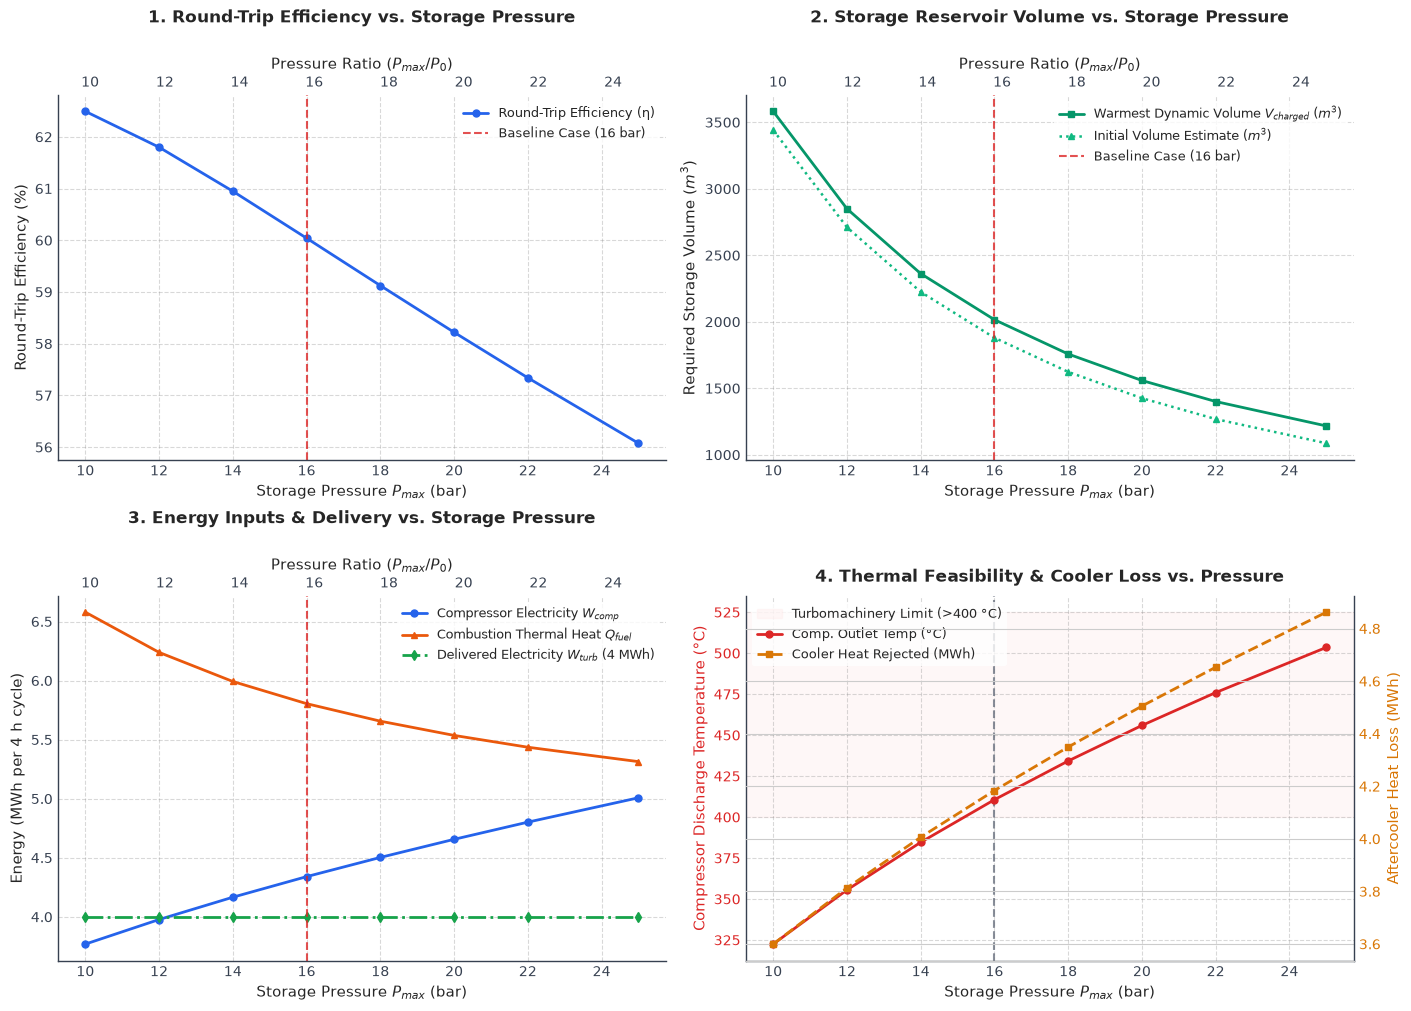

In [194]:
# ==============================================================================
# Parametric Study: 4-Panel Visualization & Trade-off Analysis (Fixed)
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np

# Set global publication-quality rcParams
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "axes.titleweight": "semibold",
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 9,
        "figure.titlesize": 14,
    }
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

# Helper function to style axes cleanly
ax_list = axes.flatten()
for ax in ax_list:
    ax.grid(True, linestyle="--", alpha=0.3, color="gray")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#374151")
    ax.spines["bottom"].set_color("#374151")
    ax.tick_params(colors="#374151", width=1)


# ------------------------------------------------------------------------------
# Plot 1: Overall Round-Trip Efficiency vs. Storage Pressure
# ------------------------------------------------------------------------------
ax1 = axes[0, 0]
ax1.plot(
    df_sweep["pressure_bar"],
    df_sweep["efficiency_pct"],
    marker="o",
    markersize=5,
    color="#2563eb",
    linewidth=2.0,
    label="Round-Trip Efficiency (η)",
)
ax1.axvline(
    16.0,
    color="#dc2626",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    label="Baseline Case (16 bar)",
)
ax1.set_xlabel("Storage Pressure $P_{max}$ (bar)")
ax1.set_ylabel("Round-Trip Efficiency (%)")
ax1.set_title("1. Round-Trip Efficiency vs. Storage Pressure", pad=25)
ax1.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none")

ax1_top = ax1.secondary_xaxis(
    "top",
    functions=(
        lambda p: np.array(p) * 1e5 / 1.013e5,
        lambda pr: np.array(pr) * 1.013e5 / 1e5,
    ),
)
ax1_top.set_xlabel("Pressure Ratio ($P_{max} / P_0$)", labelpad=5)
ax1_top.tick_params(colors="#374151")
ax1_top.spines["top"].set_visible(False)


# ------------------------------------------------------------------------------
# Plot 2: Storage Reservoir Volume vs. Storage Pressure
# ------------------------------------------------------------------------------
ax2 = axes[0, 1]
ax2.plot(
    df_sweep["pressure_bar"],
    df_sweep["v_charged_m3"],
    marker="s",
    markersize=5,
    color="#059669",
    linewidth=2.0,
    label="Warmest Dynamic Volume $V_{charged}$ ($m^3$)",
)
ax2.plot(
    df_sweep["pressure_bar"],
    df_sweep["v_initial_m3"],
    marker="^",
    markersize=5,
    color="#10b981",
    linestyle=":",
    linewidth=1.8,
    label="Initial Volume Estimate ($m^3$)",
)
ax2.axvline(
    16.0,
    color="#dc2626",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    label="Baseline Case (16 bar)",
)
ax2.set_xlabel("Storage Pressure $P_{max}$ (bar)")
ax2.set_ylabel("Required Storage Volume ($m^3$)")
ax2.set_title("2. Storage Reservoir Volume vs. Storage Pressure", pad=25)
ax2.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none")

ax2_top = ax2.secondary_xaxis(
    "top",
    functions=(
        lambda p: np.array(p) * 1e5 / 1.013e5,
        lambda pr: np.array(pr) * 1.013e5 / 1e5,
    ),
)
ax2_top.set_xlabel("Pressure Ratio ($P_{max} / P_0$)", labelpad=5)
ax2_top.tick_params(colors="#374151")
ax2_top.spines["top"].set_visible(False)


# ------------------------------------------------------------------------------
# Plot 3: Energy Breakdown (Baseline removed from legend, moved to top right)
# ------------------------------------------------------------------------------
ax3 = axes[1, 0]
ax3.plot(
    df_sweep["pressure_bar"],
    df_sweep["w_comp_mwh"],
    marker="o",
    markersize=5,
    color="#2563eb",
    linewidth=2.0,
    label="Compressor Electricity $W_{comp}$",
)
ax3.plot(
    df_sweep["pressure_bar"],
    df_sweep["q_fuel_mwh"],
    marker="^",
    markersize=5,
    color="#ea580c",
    linewidth=2.0,
    label="Combustion Thermal Heat $Q_{fuel}$",
)
ax3.plot(
    df_sweep["pressure_bar"],
    df_sweep["w_turb_mwh"],
    marker="d",
    markersize=5,
    color="#16a34a",
    linestyle="-.",
    linewidth=2.0,
    label="Delivered Electricity $W_{turb}$ (4 MWh)",
)
ax3.axvline(
    16.0, color="#dc2626", linestyle="--", linewidth=1.5, alpha=0.8
)  # Kept line, omitted from legend
ax3.set_xlabel("Storage Pressure $P_{max}$ (bar)")
ax3.set_ylabel("Energy (MWh per 4 h cycle)")
ax3.set_title("3. Energy Inputs & Delivery vs. Storage Pressure", pad=25)
ax3.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none")

ax3_top = ax3.secondary_xaxis(
    "top",
    functions=(
        lambda p: np.array(p) * 1e5 / 1.013e5,
        lambda pr: np.array(pr) * 1.013e5 / 1e5,
    ),
)
ax3_top.set_xlabel("Pressure Ratio ($P_{max} / P_0$)", labelpad=5)
ax3_top.tick_params(colors="#374151")
ax3_top.spines["top"].set_visible(False)


# ------------------------------------------------------------------------------
# Plot 4: Thermal Feasibility Limits & Cooler Waste Heat Loss (Fixed Background)
# ------------------------------------------------------------------------------
ax4 = axes[1, 1]
color_temp = "#dc2626"
color_heat = "#d97706"

# Add background span first so it doesn't wash out lines or legends
ax4.axhspan(
    400,
    525,
    color="#fee2e2",
    alpha=0.25,
    zorder=0,
    label="Turbomachinery Limit (>400 °C)",
)

line1 = ax4.plot(
    df_sweep["pressure_bar"],
    df_sweep["t_comp_out_c"],
    marker="o",
    markersize=5,
    color=color_temp,
    linewidth=2.0,
    zorder=2,
    label="Comp. Outlet Temp (°C)",
)
ax4.axvline(
    16.0,
    color="#6b7280",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    zorder=1,
)

ax4.set_xlabel("Storage Pressure $P_{max}$ (bar)")
ax4.set_ylabel(
    "Compressor Discharge Temperature (°C)", color=color_temp, fontweight="medium"
)
ax4.tick_params(axis="y", labelcolor=color_temp)

# Dual axis for aftercooler heat loss
ax4_right = ax4.twinx()
ax4_right.spines["top"].set_visible(False)
ax4_right.spines["left"].set_visible(False)
ax4_right.spines["right"].set_color("#374151")

line2 = ax4_right.plot(
    df_sweep["pressure_bar"],
    df_sweep["q_cooler_mwh"],
    marker="s",
    markersize=5,
    color=color_heat,
    linewidth=2.0,
    linestyle="--",
    zorder=2,
    label="Cooler Heat Rejected (MWh)",
)
ax4_right.set_ylabel(
    "Aftercooler Heat Loss (MWh)", color=color_heat, fontweight="medium"
)
ax4_right.tick_params(axis="y", labelcolor=color_heat)

# Combine handles cleanly including the background span label if desired
handles_4, labels_4 = ax4.get_legend_handles_labels()
handles_r, labels_r = ax4_right.get_legend_handles_labels()

ax4.legend(
    handles_4 + handles_r,
    labels_4 + labels_r,
    loc="upper left",
    frameon=True,
    facecolor="white",
    edgecolor="none",
)
ax4.set_title("4. Thermal Feasibility & Cooler Loss vs. Pressure", pad=10)

plt.show()